# Kev Decision Model: Audited Train -> Evaluate (Dev & Calibrate) -> Test Pipeline (v9)
This notebook implements the complete, end-to-end audited machine learning workflow for fine-tuning **`jaredpalmer/kev`** on your ICD-10-CM hierarchical routing and clinical evidence selection datasets:

1. **Cell 1 — Environment & Colab ABI Sanitization:** Installs `kev` and `transformers>=5.17,<6`, `peft>=0.21`, removes Google Colab's conflicting pre-installed `torchvision`, `torchaudio`, and `torchao` packages, and runs an immediate import smoke test.
2. **Cell 2 — Upload Datasets:** Uploads `train.jsonl` (6,965 records), `development.jsonl` (739 records), and `test.jsonl` (2,414 records).
3. **Cell 3 — Schema Normalization & Zero-Leakage Audit:** Promotes `_meta.task_id` $\rightarrow$ `id` and `_meta.case_id` $\rightarrow$ `group`, verifies `0` patient overlap across splits, and prints a dataset audit table.
4. **Cell 4 — Model Configuration:** Configures `jaredpalmer/kev-0.8b` (or `4b`/`9b`) and sets `KEV_DTYPE=bf16`.
5. **Cell 5 — Stage 1 (TRAIN):** Runs `kev.train` on `train.norm.jsonl` with `--device cuda --dtype bf16 --max_state 2048 --holdout 0` (since we have a dedicated `development.jsonl`), logs step-by-step loss, and plots the training curve.
6. **Cell 6 — Stage 2 (EVALUATE ON DEV & CALIBRATE):** Benchmarks both the untouched baseline and the fine-tuned model on `development.norm.jsonl`, fits the optimal temperature $T^*$ via NLL minimization on raw Dev logits, writes $T^*$ into `head.pt['temperature']`, and verifies calibrated Dev performance.
7. **Cell 7 — Stage 3 (TEST ON LOCKED HOLDOUT):** Benchmarks the untouched baseline and the calibrated fine-tuned model on `test.norm.jsonl` (2,414 records) and runs `kev.compare` paired bootstrap significance testing.
8. **Cell 8 — Stage 4 (BEFORE vs. AFTER DASHBOARD):** Computes overall, per-task, and special-label metrics (`Accuracy`, `Brier`, `NLL`, `ECE`, `Confident Errors`, `Coverage @ <=5% Error`), **Case-Level Full ICD-10 Trajectory Exact Match**, and plots Reliability & Selective Automation curves.
9. **Cell 9 — Qualitative Win/Loss Analysis:** Inspects newly fixed vs. newly regressed questions on the locked test set.
10. **Cell 10 — Export Archive:** Packages the calibrated checkpoint, evaluation runs, CSV tables, and charts for download.

In [ ]:
# @title 1. Environment Setup, Colab ABI Sanitization & Smoke Test
import os
import subprocess

!nvidia-smi
if not os.path.exists('/content/kev'):
    !git clone https://github.com/jaredpalmer/kev.git /content/kev
%cd /content/kev

# 1. Remove Colab pre-installed packages that cause C++ ABI / PEFT version clashes:
#    - torchvision / torchaudio: causes `RuntimeError: operator torchvision::nms does not exist`
#    - torchao (0.10.0 in Colab): causes `ImportError: Found an incompatible version of torchao` in peft>=0.21
!pip uninstall -y -q torchvision torchaudio torchao

# 2. Install required packages without breaking Colab's CUDA torch build
!pip install -q --upgrade "transformers>=5.17,<6" "peft>=0.21" accelerate huggingface_hub safetensors fastapi uvicorn pydantic pandas matplotlib tabulate scipy
!pip install -q --no-deps -e .
# Ensure none of the upgraded packages re-pulled torchvision/torchao
!pip uninstall -y -q torchvision torchaudio torchao

# 3. Pre-flight Smoke Test: verify Qwen3_5, PEFT, and Kev modules import cleanly
smoke_cmd = [
    'python', '-c',
    'import torch, transformers, peft; '
    'from transformers import AutoModelForCausalLM; '
    'import kev.model, kev.train, kev.benchmark, kev.compare, kev.calibrate; '
    'print("SMOKE TEST PASSED -> Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(), '
    '"| Transformers:", transformers.__version__, "| PEFT:", peft.__version__)'
]
res = subprocess.run(smoke_cmd, capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Environment smoke test failed!')

Wed Nov 11 13:57:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# @title 2. Upload `train.jsonl`, `development.jsonl`, and `test.jsonl`
import os
from google.colab import files

os.makedirs('/content/kev/data', exist_ok=True)
os.makedirs('/content/kev/logs', exist_ok=True)
os.makedirs('/content/kev/runs', exist_ok=True)

required_files = ['train.jsonl', 'development.jsonl', 'test.jsonl']
missing = [f for f in required_files if not os.path.exists(f'/content/kev/data/{f}')]

if missing:
    print(f'Please upload missing files {missing}:')
    uploaded = files.upload()
    for fn in uploaded.keys():
        os.replace(fn, f'/content/kev/data/{fn}')
        print(f'Saved to /content/kev/data/{fn}')
else:
    print('All three dataset files already exist in /content/kev/data/.')

Please upload missing files ['train.jsonl', 'development.jsonl', 'test.jsonl']:


Saving development.jsonl to development.jsonl
Saving test.jsonl to test.jsonl
Saving train.jsonl to train.jsonl
Saved to /content/kev/data/development.jsonl
Saved to /content/kev/data/test.jsonl
Saved to /content/kev/data/train.jsonl


In [ ]:
# @title 3. Schema Normalization (`_meta.task_id` -> `id`, `_meta.case_id` -> `group`) & Zero-Leakage Audit
import json
import pandas as pd
from collections import Counter

def normalize_split(in_path, out_path, split_label):
    records = []
    with open(in_path, 'r', encoding='utf-8') as f:
        for idx, line in enumerate(f):
            if not line.strip():
                continue
            r = json.loads(line)
            meta = r.get('_meta', {})
            # 1. Promote unique task_id to top-level 'id' for kev.benchmark & kev.compare
            if 'id' not in r:
                r['id'] = meta.get('task_id', f'{split_label}-{idx}')
            # 2. Promote case_id to 'group' so kev.calibrate & kev.compare cluster by patient case
            if 'group' not in r and 'case_id' in meta:
                r['group'] = meta['case_id']
            records.append(r)

    with open(out_path, 'w', encoding='utf-8') as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
    return records

train_recs = normalize_split('/content/kev/data/train.jsonl', '/content/kev/data/train.norm.jsonl', 'train')
dev_recs   = normalize_split('/content/kev/data/development.jsonl', '/content/kev/data/development.norm.jsonl', 'dev')
test_recs  = normalize_split('/content/kev/data/test.jsonl', '/content/kev/data/test.norm.jsonl', 'test')

# Verify zero case_id leakage across Train, Dev, and Test
train_cases = set(r['_meta']['case_id'] for r in train_recs)
dev_cases   = set(r['_meta']['case_id'] for r in dev_recs)
test_cases  = set(r['_meta']['case_id'] for r in test_recs)

assert len(train_cases & dev_cases) == 0, 'DATA LEAKAGE: Train and Dev share case_ids!'
assert len(train_cases & test_cases) == 0, 'DATA LEAKAGE: Train and Test share case_ids!'
assert len(dev_cases & test_cases) == 0, 'DATA LEAKAGE: Dev and Test share case_ids!'
print('No Shared Case IDs Across Splits: Train, Development, and Test splits share 0 patient case_ids.\n')

summary_rows = []
for name, recs in [('Train', train_recs), ('Development (Eval)', dev_recs), ('Test (Holdout)', test_recs)]:
    t_counts = Counter(r.get('_meta', {}).get('task_type', 'unknown') for r in recs)
    q_counts = Counter(q['type'] for r in recs for q in r['questions'].values())
    summary_rows.append({
        'Split': name,
        'Records': len(recs),
        'Unique Cases': len(set(r['_meta']['case_id'] for r in recs)),
        'Total Questions': sum(q_counts.values()),
        'Routing (Choice)': t_counts.get('routing', 0),
        'No-Match (Choice)': t_counts.get('routing_no_match', 0),
        'Evidence (Noul)': t_counts.get('evidence_selection', 0),
        'Choice Qs': q_counts.get('choice', 0),
        'Noul Qs': q_counts.get('noul', 0),
    })

df_audit = pd.DataFrame(summary_rows)
print(df_audit.to_string(index=False))

No Shared Case IDs Across Splits: Train, Development, and Test splits share 0 patient case_ids.

             Split  Records  Unique Cases  Total Questions  Routing (Choice)  No-Match (Choice)  Evidence (Noul)  Choice Qs  Noul Qs
             Train     6965           952             9222              4607               1572              786       6179     3043
Development (Eval)      739            97             1001               490                166               83        656      345
    Test (Holdout)     2414           332             3247              1598                544              272       2142     1105


In [14]:
# @title 4. Model Configuration & Hyperparameters
import os

# Select '0.8b' for fast Colab T4 runs (~2-3 hrs), or '4b' for L4/A100 (~45 mins)
MODEL_SIZE = '0.8b' # @param ['0.8b', '4b', '9b']
EPOCHS = 2 # @param {type:"integer"}
BATCH_SIZE = 1 # @param {type:"integer"}
GRAD_ACCUM = 8 # @param {type:"integer"}
MAX_STATE_TOKENS = 2048 # @param {type:"integer"}

# Use clean Hub repo IDs (compatible with both PeftModel.from_pretrained and kev.checkpoint)
MODEL_MAP = {
    '0.8b': ('Qwen/Qwen3.5-0.8B-Base', 'jaredpalmer/kev-0.8b', '4e-5'),
    '4b':   ('Qwen/Qwen3.5-4B-Base',   'jaredpalmer/kev-4b',   '2e-5'),
    '9b':   ('Qwen/Qwen3.5-9B-Base',   'jaredpalmer/kev-9b',   '2e-5'),
}

BASE_MODEL, INIT_CKPT, LR = MODEL_MAP[MODEL_SIZE]
os.environ['BASE_MODEL'] = BASE_MODEL
os.environ['INIT_CKPT'] = INIT_CKPT
os.environ['LR'] = LR
os.environ['EPOCHS'] = str(EPOCHS)
os.environ['BATCH_SIZE'] = str(BATCH_SIZE)
os.environ['GRAD_ACCUM'] = str(GRAD_ACCUM)
os.environ['MAX_STATE'] = str(MAX_STATE_TOKENS)
os.environ['KEV_DTYPE'] = 'bf16'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

print(f'Configured Base   : {BASE_MODEL}')
print(f'Init Checkpoint   : {INIT_CKPT}')
print(f'Learning Rate     : {LR} | Epochs: {EPOCHS} | Effective Batch: {BATCH_SIZE * GRAD_ACCUM} | Max State: {MAX_STATE_TOKENS}')

Configured Base   : Qwen/Qwen3.5-0.8B-Base
Init Checkpoint   : jaredpalmer/kev-0.8b
Learning Rate     : 4e-5 | Epochs: 2 | Effective Batch: 8 | Max State: 2048


Running command: python -u -m kev.train --data /content/kev/data/train.norm.jsonl --base Qwen/Qwen3.5-0.8B-Base --init_from jaredpalmer/kev-0.8b --lr 4e-5 --epochs 2 --batch 1 --accum 8 --holdout 0 --device cuda --dtype bf16 --max_state 2048 --out /content/kev/runs/kev-icd10-ft
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

Loading weights: 100%|██████████| 320/320 [00:01<00:00, 203.17it/s]

Fetching 9 files: 100%|██████████| 9/9 [00:01<00:00,  6.49it/s]
delta: warm start from /root/.cache/huggingface/hub/models--jaredpalmer--kev-0.8b/snapshots/bf75a6a8848ea6960ff2ed108d9ed44c2941174f: 372 lora tensors and the pointer head loaded
device=cuda world=1 trainable params=11.3M
6965 training requests (holdout=['0']), questions by type {'choice': 6179, 'noul': 3043}
[transformers] `causal_conv1d_fn` is falling back to its reference

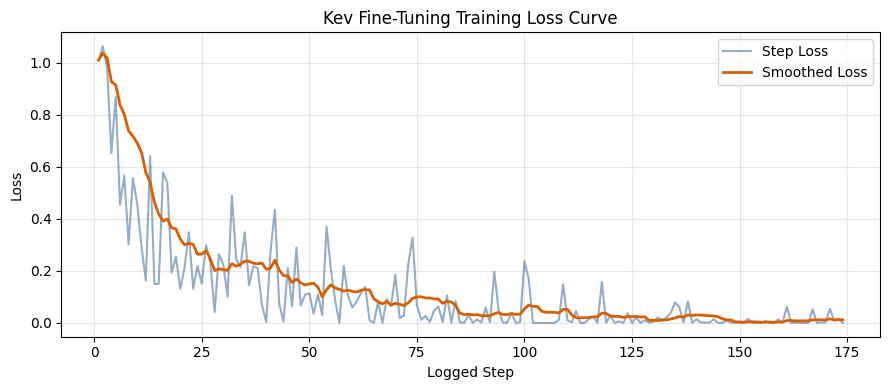

In [ ]:
# @title 5. STAGE 1 — TRAIN: Fine-Tune Kev on `train.norm.jsonl` with Live Loss Logging & Curve Plot
import json
import os
import re
import shutil
import subprocess
import torch
import pandas as pd
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), 'CUDA GPU not detected! In Colab, go to Runtime -> Change runtime type -> T4/L4/A100 GPU.'

out_dir = '/content/kev/runs/kev-icd10-ft'
log_path = '/content/kev/logs/train.log'

# Clear any previous run directory so kev.train never fails with 'refusing to overwrite an existing run'
if os.path.exists(out_dir):
    shutil.rmtree(out_dir)
    print(f'Cleared previous directory: {out_dir}')

train_cmd = [
    'python', '-u', '-m', 'kev.train',
    '--data', '/content/kev/data/train.norm.jsonl',
    '--base', os.environ['BASE_MODEL'],
    '--init_from', os.environ['INIT_CKPT'],
    '--lr', os.environ['LR'],
    '--epochs', os.environ['EPOCHS'],
    '--batch', os.environ['BATCH_SIZE'],
    '--accum', os.environ['GRAD_ACCUM'],
    '--holdout', '0',
    '--device', 'cuda',
    '--dtype', 'bf16',
    '--max_state', os.environ['MAX_STATE'],
    '--out', out_dir,
]

print('Running command:', ' '.join(train_cmd))
with open(log_path, 'w', encoding='utf-8') as lf:
    proc = subprocess.Popen(train_cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end='')
        lf.write(line)
    ret = proc.wait()

if ret != 0 or not os.path.exists(f'{out_dir}/head.pt'):
    raise RuntimeError(f'kev.train exited with code {ret}. Check log output above.')

print(f'\nSUCCESS: Fine-tuned checkpoint saved to {out_dir}/head.pt')

# Display training_metrics.json if generated by kev.train
metrics_json_path = f'{out_dir}/training_metrics.json'
if os.path.exists(metrics_json_path):
    with open(metrics_json_path) as mf:
        t_metrics = json.load(mf)
    print('=== training_metrics.json ===')
    print(json.dumps(t_metrics, indent=2)[:1500])

# Parse training log for loss progression and plot learning curve
losses = []
with open(log_path, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        m = re.search(r'loss[=:\s]+([0-9]+\.[0-9]+)', line, re.IGNORECASE)
        if m:
            losses.append(float(m.group(1)))

if losses:
    plt.figure(figsize=(9, 4))
    plt.plot(range(1, len(losses) + 1), losses, label='Step Loss', alpha=0.5, color='#2b5c8f')
    if len(losses) >= 5:
        smooth = pd.Series(losses).rolling(max(3, len(losses)//15), min_periods=1).mean()
        plt.plot(range(1, len(losses) + 1), smooth, label='Smoothed Loss', linewidth=2, color='#d95f02')
    plt.title('Kev Fine-Tuning Training Loss Curve')
    plt.xlabel('Logged Step')
    plt.ylabel('Loss')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig('/content/kev/logs/training_loss_curve.png', dpi=150)
    plt.show()

In [ ]:
# @title 6. STAGE 2 — EVALUATE (DEV) & CALIBRATE: Full GPU Benchmark on `development.norm.jsonl` & Calibrate `head.pt`
import json
import os
import re
import shutil
import subprocess
import torch

os.environ.setdefault('BASE_MODEL', 'Qwen/Qwen3.5-0.8B-Base')
os.environ.setdefault('INIT_CKPT', 'jaredpalmer/kev-0.8b')
os.environ.setdefault('KEV_DTYPE', 'bf16')

def safe_remove(p):
    if os.path.isfile(p) or os.path.islink(p):
        os.remove(p)
    elif os.path.isdir(p):
        shutil.rmtree(p)

def run_cmd(cmd, tee_path=None):
    print('>>>', ' '.join(cmd))
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    lines = []
    for line in proc.stdout:
        print(line, end='')
        lines.append(line)
    ret = proc.wait()
    if tee_path:
        with open(tee_path, 'w', encoding='utf-8') as f:
            f.writelines(lines)
    if ret != 0:
        raise RuntimeError(f'Command failed with exit code {ret}: {" ".join(cmd)}')
    return ''.join(lines)

def resolve_rows_file(run_dir):
    for fname in ['rows.json', 'rows.jsonl']:
        p = os.path.join(run_dir, fname)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Neither rows.json nor rows.jsonl found in {run_dir}: {os.listdir(run_dir)}')

for d in [
    '/content/kev/runs/dev-baseline-eval',
    '/content/kev/runs/dev-finetuned-uncal-eval',
    '/content/kev/runs/dev-finetuned-cal-eval',
    '/content/kev/runs/dev-compare',
    '/content/kev/runs/dev-compare.json',
]:
    safe_remove(d)

print('--- [2A] Benchmarking Untouched Pre-Trained Baseline on DEVELOPMENT Set (739 records / 1,001 questions) ---')
run_cmd([
    'python', '-u', '-m', 'kev.benchmark',
    '--run', os.environ['INIT_CKPT'],
    '--data', '/content/kev/data/development.norm.jsonl',
    '--out', '/content/kev/runs/dev-baseline-eval'
], tee_path='/content/kev/logs/dev_baseline_benchmark.txt')

print('\n--- [2B] Benchmarking Fine-Tuned Model (Pre-Calibration, T=1.0) on DEVELOPMENT Set (739 records) ---')
head_pt_path = '/content/kev/runs/kev-icd10-ft/head.pt'
head_state = torch.load(head_pt_path, map_location='cpu', weights_only=False)
head_state['temperature'] = 1.0
torch.save(head_state, head_pt_path)

run_cmd([
    'python', '-u', '-m', 'kev.benchmark',
    '--run', '/content/kev/runs/kev-icd10-ft',
    '--data', '/content/kev/data/development.norm.jsonl',
    '--out', '/content/kev/runs/dev-finetuned-uncal-eval'
], tee_path='/content/kev/logs/dev_finetuned_uncal_benchmark.txt')

uncal_rows_file = resolve_rows_file('/content/kev/runs/dev-finetuned-uncal-eval')
print(f'\n--- [2C] Fitting Optimal Temperature on DEVELOPMENT Set ({uncal_rows_file}) ---')
cal_out = run_cmd([
    'python', '-u', '-m', 'kev.calibrate',
    '--rows', uncal_rows_file
], tee_path='/content/kev/logs/dev_calibrate.txt')

fitted_T = None
m_T = re.search(r'workload\s+T=([0-9]+\.?[0-9]*)', cal_out)
if m_T:
    fitted_T = float(m_T.group(1))

cal_json_path = '/content/kev/runs/dev-finetuned-uncal-eval/calibration.json'
if fitted_T is None and os.path.exists(cal_json_path):
    with open(cal_json_path, 'r', encoding='utf-8') as f:
        cal_data = json.load(f)
    for k in ['workload_temperature', 'temperature', 'T', 'oof_temperature']:
        if isinstance(cal_data.get(k), (int, float)) and cal_data[k] > 0:
            fitted_T = float(cal_data[k])
            break
    if fitted_T is None and isinstance(cal_data.get('workload'), dict):
        for tk in ['temperature', 'T']:
            if isinstance(cal_data['workload'].get(tk), (int, float)):
                fitted_T = float(cal_data['workload'][tk])
                break

if fitted_T is None or fitted_T <= 0:
    fitted_T = 1.0

head_state['temperature'] = float(fitted_T)
torch.save(head_state, head_pt_path)
print(f'\nPersisted calibrated head.pt["temperature"] = {fitted_T:.4f} into {head_pt_path}')

print(f'\n--- [2D] Benchmarking Calibrated Fine-Tuned Model (T={fitted_T:.2f}) on DEVELOPMENT Set (739 records) ---')
run_cmd([
    'python', '-u', '-m', 'kev.benchmark',
    '--run', '/content/kev/runs/kev-icd10-ft',
    '--data', '/content/kev/data/development.norm.jsonl',
    '--out', '/content/kev/runs/dev-finetuned-cal-eval'
], tee_path='/content/kev/logs/dev_finetuned_cal_benchmark.txt')

print('\n--- [2E] Paired Bootstrap Comparison on DEVELOPMENT Set (Calibrated Fine-Tuned vs. Baseline) ---')
run_cmd([
    'python', '-u', '-m', 'kev.compare',
    '--candidate', '/content/kev/runs/dev-finetuned-cal-eval',
    '--reference', '/content/kev/runs/dev-baseline-eval',
    '--out', '/content/kev/runs/dev-compare.json'
], tee_path='/content/kev/logs/dev_compare.txt')

--- [2A] Benchmarking Untouched Pre-Trained Baseline on DEVELOPMENT Set (739 records / 1,001 questions) ---
>>> python -u -m kev.benchmark --run jaredpalmer/kev-0.8b --data /content/kev/data/development.norm.jsonl --out /content/kev/runs/dev-baseline-eval
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 1385.12it/s]

Loading weights: 100%|██████████| 320/320 [00:00<00:00, 4654.99it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; in

'/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version \'1.5.0\' or newer of \'bottleneck\' (version \'1.4.2\' currently installed).\n  from pandas.core import (\ntask                 kev acc    Jev acc    kev NLL    Jev NLL\ncustom_choice           0.992      0.732      0.036      1.214\ncustom_noul             0.980      0.310      0.045      1.384\n{\n  "paired": {\n    "nll": {\n      "macro_nll_delta": -1.2583545894517596,\n      "ci95": [\n        -1.2969309847975425,\n        -1.2152200452894937\n      ],\n      "samples": 1000,\n      "groups": 739,\n      "aggregation": "macro",\n      "unit": "source-stratified original record; sibling questions stay together",\n      "method": "paired cluster percentile bootstrap; full statistic recomputed in each resample"\n    },\n    "acc": {\n      "macro_acc_delta": 0.46511797454931075,\n      "ci95": [\n        0.4435263804448107,\n        0.48796642357719194\n      ],\n      "sam

In [ ]:
# @title 7. STAGE 3 — TEST (LOCKED HOLDOUT): Benchmark Before vs. After Fine-Tuning on `test.norm.jsonl`
import os
import shutil
import subprocess

os.environ.setdefault('INIT_CKPT', 'jaredpalmer/kev-0.8b')
os.environ.setdefault('KEV_DTYPE', 'bf16')

def safe_remove(p):
    if os.path.isfile(p) or os.path.islink(p):
        os.remove(p)
    elif os.path.isdir(p):
        shutil.rmtree(p)

def run_cmd(cmd, tee_path=None):
    print('>>>', ' '.join(cmd))
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    lines = []
    for line in proc.stdout:
        print(line, end='')
        lines.append(line)
    ret = proc.wait()
    if tee_path:
        with open(tee_path, 'w', encoding='utf-8') as f:
            f.writelines(lines)
    if ret != 0:
        raise RuntimeError(f'Command failed with exit code {ret}: {" ".join(cmd)}')
    return ''.join(lines)

for d in [
    '/content/kev/runs/test-baseline-eval',
    '/content/kev/runs/test-finetuned-eval',
    '/content/kev/runs/test-compare',
    '/content/kev/runs/test-compare.json',
]:
    safe_remove(d)

print('--- [3A] Benchmarking Pre-Trained Baseline on Locked TEST Set (2,414 records / 3,247 questions) ---')
run_cmd([
    'python', '-u', '-m', 'kev.benchmark',
    '--run', os.environ['INIT_CKPT'],
    '--data', '/content/kev/data/test.norm.jsonl',
    '--out', '/content/kev/runs/test-baseline-eval'
], tee_path='/content/kev/logs/test_baseline_benchmark.txt')

print('\n--- [3B] Benchmarking Fine-Tuned + Calibrated Model on Locked TEST Set (2,414 records / 3,247 questions) ---')
run_cmd([
    'python', '-u', '-m', 'kev.benchmark',
    '--run', '/content/kev/runs/kev-icd10-ft',
    '--data', '/content/kev/data/test.norm.jsonl',
    '--out', '/content/kev/runs/test-finetuned-eval'
], tee_path='/content/kev/logs/test_finetuned_benchmark.txt')

print('\n--- [3C] Official Kev Paired Bootstrap Comparison on Locked TEST Set ---')
run_cmd([
    'python', '-u', '-m', 'kev.compare',
    '--candidate', '/content/kev/runs/test-finetuned-eval',
    '--reference', '/content/kev/runs/test-baseline-eval',
    '--out', '/content/kev/runs/test-compare.json'
], tee_path='/content/kev/logs/test_compare.txt')

--- [3A] Benchmarking Pre-Trained Baseline on Locked TEST Set (2,414 records / 3,247 questions) ---
>>> python -u -m kev.benchmark --run jaredpalmer/kev-0.8b --data /content/kev/data/test.norm.jsonl --out /content/kev/runs/test-baseline-eval
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 1320.72it/s]

Loading weights: 100%|██████████| 320/320 [00:00<00:00, 4691.34it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-l

'/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version \'1.5.0\' or newer of \'bottleneck\' (version \'1.4.2\' currently installed).\n  from pandas.core import (\ntask                 kev acc    Jev acc    kev NLL    Jev NLL\ncustom_choice           0.990      0.720      0.027      1.248\ncustom_noul             0.984      0.318      0.056      1.374\n{\n  "paired": {\n    "nll": {\n      "macro_nll_delta": -1.268842237865818,\n      "ci95": [\n        -1.2932360461576575,\n        -1.2424576336273152\n      ],\n      "samples": 1000,\n      "groups": 2414,\n      "aggregation": "macro",\n      "unit": "source-stratified original record; sibling questions stay together",\n      "method": "paired cluster percentile bootstrap; full statistic recomputed in each resample"\n    },\n    "acc": {\n      "macro_acc_delta": 0.4679523091287797,\n      "ci95": [\n        0.45485557794967896,\n        0.48036990680187713\n      ],\n      "sam

In [3]:
# @title 7.5 RESUME SESSION — Upload `kev-icd10-complete-results.tar.gz` & `test.jsonl`
import json
import os
import tarfile
from google.colab import files

os.makedirs('/content/kev/data', exist_ok=True)
os.makedirs('/content/kev/runs', exist_ok=True)
os.makedirs('/content/kev/logs', exist_ok=True)

print("Please upload BOTH `kev-icd10-complete-results.tar.gz` and `test.jsonl`:")
uploaded = files.upload()

for fn in uploaded.keys():
    if fn.endswith('.tar.gz') or fn.endswith('.tgz'):
        print(f"Extracting {fn} into /content/kev/ ...")
        with tarfile.open(fn, 'r:gz') as tar:
            tar.extractall('/content/kev')
        os.remove(fn)
        print("Extracted runs/ and logs/ successfully!")
    elif fn.endswith('.jsonl'):
        target_name = 'test.jsonl' if 'test' in fn.lower() else fn
        os.replace(fn, f'/content/kev/data/{target_name}')
        print(f"Saved /content/kev/data/{target_name}")

# Regenerate /content/kev/data/test.norm.jsonl if needed
if os.path.exists('/content/kev/data/test.jsonl') and not os.path.exists('/content/kev/data/test.norm.jsonl'):
    count = 0
    with open('/content/kev/data/test.jsonl', 'r', encoding='utf-8') as fin, \
         open('/content/kev/data/test.norm.jsonl', 'w', encoding='utf-8') as fout:
        for idx, line in enumerate(fin):
            if not line.strip():
                continue
            r = json.loads(line)
            meta = r.get('_meta', {})
            if 'id' not in r:
                r['id'] = meta.get('task_id', f'test-{idx}')
            if 'group' not in r and 'case_id' in meta:
                r['group'] = meta['case_id']
            fout.write(json.dumps(r, ensure_ascii=False) + '\n')
            count += 1
    print(f"Regenerated /content/kev/data/test.norm.jsonl ({count} records).")

# Verify everything is ready for Cell 8 & Cell 9
assert os.path.exists('/content/kev/runs/test-baseline-eval'), "Missing /content/kev/runs/test-baseline-eval! Did you upload kev-icd10-complete-results.tar.gz?"
assert os.path.exists('/content/kev/runs/test-finetuned-eval'), "Missing /content/kev/runs/test-finetuned-eval! Did you upload kev-icd10-complete-results.tar.gz?"
assert os.path.exists('/content/kev/data/test.norm.jsonl'), "Missing /content/kev/data/test.norm.jsonl! Please upload test.jsonl."
print("\nREADY! You can now run Cell 8 and Cell 9 below.")

Please upload BOTH `kev-icd10-complete-results.tar.gz` and `test.jsonl`:


Saving kev-icd10-complete-results.tar.gz to kev-icd10-complete-results.tar.gz
Saving test.jsonl to test.jsonl
Extracting kev-icd10-complete-results.tar.gz into /content/kev/ ...


/tmp/ipykernel_1036/686035567.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content/kev')


Extracted runs/ and logs/ successfully!
Saved /content/kev/data/test.jsonl
Regenerated /content/kev/data/test.norm.jsonl (2414 records).

READY! You can now run Cell 8 and Cell 9 below.


=== Official kev.benchmark report.json: Dev Baseline (Before FT) ===
{'n': 1001, 'acc': 0.5864, 'brier': 0.7043, 'nll': 1.2722, 'ece': 0.3872, 'confident_error_rate': 0.0729, 'coverage_at_5pct_error': 0.0, 'coverage_at_1pct_error': 0.0, 'aurc': 0.4674} 

=== Official kev.benchmark report.json: Dev Fine-Tuned (Uncalibrated T=1.0) ===
{'n': 1001, 'acc': 0.988, 'brier': 0.0199, 'nll': 0.0686, 'ece': 0.0104, 'confident_error_rate': 0.009, 'coverage_at_5pct_error': 1.0, 'coverage_at_1pct_error': 0.997, 'aurc': 0.0005} 

=== Official kev.benchmark report.json: Dev Fine-Tuned (Calibrated) ===
{'n': 1001, 'acc': 0.988, 'brier': 0.0177, 'nll': 0.0388, 'ece': 0.0081, 'confident_error_rate': 0.002, 'coverage_at_5pct_error': 1.0, 'coverage_at_1pct_error': 0.997, 'aurc': 0.0005} 

=== Official kev.benchmark report.json: Test Baseline (Before FT) ===
{'n': 3247, 'acc': 0.5833, 'brier': 0.7077, 'nll': 1.2905, 'ece': 0.3818, 'confident_error_rate': 0.0776, 'coverage_at_5pct_error': 0.0003, 'coverage_a

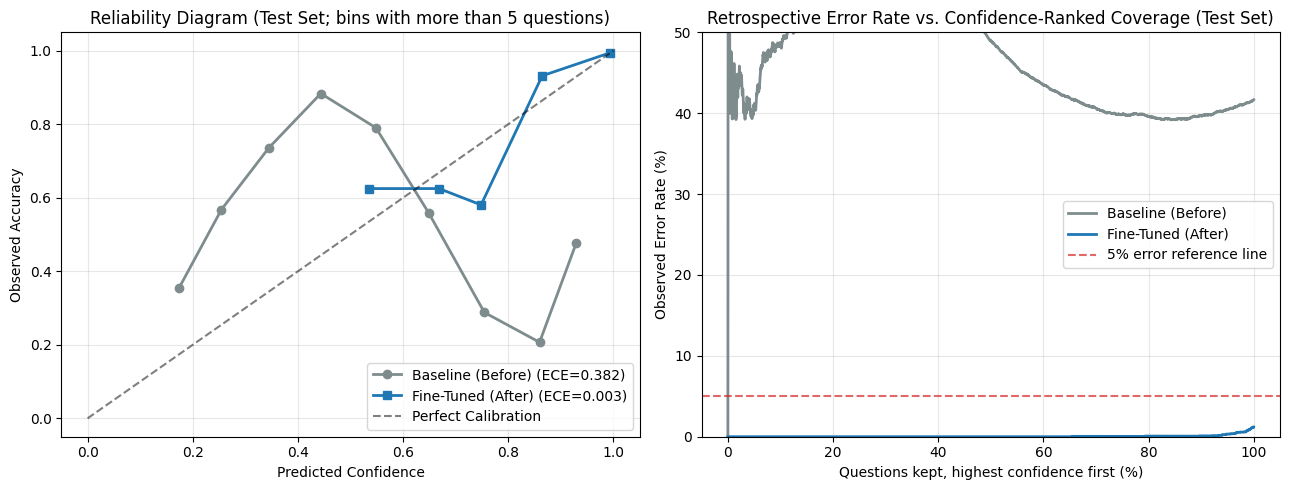

In [16]:
# @title 8. STAGE 4 — Comprehensive Before vs. After Evaluation Dashboard & Visual Charts
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Print official kev.benchmark report.json summaries
for label, r_dir in [
    ('Dev Baseline (Before FT)', '/content/kev/runs/dev-baseline-eval'),
    ('Dev Fine-Tuned (Uncalibrated T=1.0)', '/content/kev/runs/dev-finetuned-uncal-eval'),
    ('Dev Fine-Tuned (Calibrated)', '/content/kev/runs/dev-finetuned-cal-eval'),
    ('Test Baseline (Before FT)', '/content/kev/runs/test-baseline-eval'),
    ('Test Fine-Tuned (After FT, Calibrated)', '/content/kev/runs/test-finetuned-eval'),
]:
    if not os.path.exists(r_dir):
        continue
    for fn in ['report.json', 'result.json']:
        p = os.path.join(r_dir, fn)
        if os.path.exists(p):
            data = json.load(open(p))
            clean = data.get('clean', data)
            print(f'=== Official kev.benchmark {fn}: {label} ===')
            print({k: round(clean[k], 4) if isinstance(clean.get(k), float) else clean.get(k)
                   for k in ['n', 'acc', 'brier', 'nll', 'ece', 'confident_error_rate', 'coverage_at_5pct_error', 'coverage_at_1pct_error', 'aurc']
                   if k in clean}, '\n')
            break

# 2. Load ordered question metadata & option lists from test.norm.jsonl
meta_by_key = {}
meta_ordered = []
with open('/content/kev/data/test.norm.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if not line.strip():
            continue
        r = json.loads(line)
        rid = r['id']
        m = r.get('_meta', {})
        for q_name, q_obj in r['questions'].items():
            q_type = q_obj.get('type', 'unknown')
            lbl = q_obj.get('label')
            if q_type == 'choice':
                opts = list(q_obj.get('criteria', {}).keys())
                gold_str = str(lbl)
            else:
                opts = ['false', 'true']
                gold_str = 'true' if lbl is True or str(lbl).lower() in ('true', 'yes', '1') else 'false'
            info = {
                'rid': rid,
                'q_name': q_name,
                'case_id': m.get('case_id', rid.split(':')[0]),
                'task_type': m.get('task_type', 'unknown'),
                'q_type': q_type,
                'gold_label': gold_str,
                'options': opts,
            }
            meta_ordered.append(info)
            meta_by_key[(rid, q_name)] = info
            meta_by_key[(f'{rid}:{q_name}', None)] = info
            meta_by_key[(f'{rid}/{q_name}', None)] = info
            if len(r['questions']) == 1:
                meta_by_key[(rid, None)] = info

def softmax_1d(x):
    x = np.asarray(x, dtype=np.float64)
    x = x - np.max(x)
    e = np.exp(x)
    return e / np.sum(e)

def parse_kev_rows(run_dir):
    rows_path = os.path.join(run_dir, 'rows.json') if os.path.exists(os.path.join(run_dir, 'rows.json')) else os.path.join(run_dir, 'rows.jsonl')
    raw_text = open(rows_path, 'r', encoding='utf-8').read().strip()
    raw_obj = json.loads(raw_text) if raw_text.startswith('[') or raw_text.startswith('{') else [json.loads(l) for l in raw_text.splitlines() if l.strip()]
    if isinstance(raw_obj, dict):
        for k in ['rows', 'items', 'clean', 'predictions']:
            if isinstance(raw_obj.get(k), list):
                raw_obj = raw_obj[k]
                break

    if len(raw_obj) > 0:
        print(f'[{os.path.basename(run_dir)}] Loaded {len(raw_obj)} rows | Sample row keys: {list(raw_obj[0].keys())}')

    parsed = []
    for idx, row in enumerate(raw_obj):
        rid = row.get('id') or row.get('record_id') or row.get('task_id') or row.get('row_id')
        q_name = row.get('question') or row.get('q') or row.get('question_id') or row.get('name')

        info = None
        if rid is not None and q_name is not None:
            info = meta_by_key.get((str(rid), str(q_name)))
        if info is None and isinstance(rid, str):
            info = meta_by_key.get((rid, None))
            if info is None:
                for sep in [':', '/', '.']:
                    if sep in rid:
                        p0, p1 = rid.rsplit(sep, 1)
                        if (p0, p1) in meta_by_key:
                            info = meta_by_key[(p0, p1)]
                            break
        if info is None and idx < len(meta_ordered):
            info = meta_ordered[idx]

        rid_final = info['rid'] if info else str(rid)
        q_final   = info['q_name'] if info else str(q_name or 'route')
        case_id   = info['case_id'] if info else str(rid_final).split(':')[0]
        task_type = info['task_type'] if info else 'unknown'
        q_type    = row.get('type') or (info['q_type'] if info else 'unknown')
        opts      = row.get('options') or row.get('keys') or (info['options'] if info else [])
        gold_str  = info['gold_label'] if info else str(row.get('label', row.get('gold', '')))

        p_vec = None
        for pk in ['probs', 'probabilities', 'p', 'dist', 'scores']:
            if pk in row and row[pk] is not None:
                p_vec = row[pk]
                break
        if p_vec is None:
            for lk in ['logits', 'log_probs', 'logprobs']:
                if lk in row and row[lk] is not None:
                    l_val = row[lk]
                    p_vec = {k: float(v) for k, v in zip(l_val.keys(), softmax_1d(list(l_val.values())))} if isinstance(l_val, dict) else list(softmax_1d(l_val))
                    break

        target_idx = row.get('target') if isinstance(row.get('target'), int) and not isinstance(row.get('target'), bool) else None
        if target_idx is None and isinstance(row.get('label'), int) and not isinstance(row.get('label'), bool):
            target_idx = row['label']

        if isinstance(p_vec, list) and len(p_vec) > 0:
            arr = np.asarray(p_vec, dtype=np.float64)
            if np.any(arr < 0.0) or not np.isclose(np.sum(arr), 1.0, atol=1e-2):
                arr = softmax_1d(arr)
            pred_idx = int(np.argmax(arr))
            conf = float(arr[pred_idx])
            if target_idx is not None and 0 <= target_idx < len(arr):
                g_idx = target_idx
            elif gold_str in opts:
                g_idx = opts.index(gold_str)
            else:
                g_idx = 0
            p_gold = float(arr[g_idx])
            one_hot = np.zeros_like(arr)
            one_hot[g_idx] = 1.0
            brier = float(np.sum((arr - one_hot) ** 2))
            correct = int(pred_idx == g_idx)
            pred_str = opts[pred_idx] if len(opts) == len(arr) else str(pred_idx)
        elif isinstance(p_vec, dict) and len(p_vec) > 0:
            pred_str, conf = max(p_vec.items(), key=lambda x: float(x[1]))
            conf = float(conf)
            p_gold = float(p_vec.get(gold_str, 1e-12))
            brier = float(sum((float(v) - (1.0 if str(k) == gold_str else 0.0))**2 for k, v in p_vec.items()))
            correct = int(str(pred_str) == gold_str)
        elif isinstance(p_vec, (int, float)):
            p_true = float(np.clip(p_vec, 0.0, 1.0))
            pred_str = 'true' if p_true >= 0.5 else 'false'
            conf = p_true if pred_str == 'true' else (1.0 - p_true)
            p_gold = p_true if gold_str == 'true' else (1.0 - p_true)
            brier = float(2.0 * ((1.0 - p_gold) ** 2))
            correct = int(pred_str == gold_str)
        else:
            correct = int(bool(row.get('correct', row.get('acc', 0))))
            conf = float(row.get('confidence', row.get('conf', row.get('mean_conf', 0.5))))
            brier = float(row.get('brier', (1.0 - conf)**2 if correct else conf**2))
            p_gold = float(row.get('p_gold', conf if correct else max(1.0 - conf, 1e-12)))
            pred_str = gold_str if correct else 'WRONG'

        if 'correct' in row and isinstance(row['correct'], (bool, int)):
            correct = int(bool(row['correct']))
        if 'brier' in row and isinstance(row['brier'], (int, float)):
            brier = float(row['brier'])
        nll = float(row['nll']) if isinstance(row.get('nll'), (int, float)) else float(-np.log(max(p_gold, 1e-12)))

        parsed.append({
            'id': rid_final,
            'case_id': case_id,
            'question': q_final,
            'task_type': task_type,
            'q_type': q_type,
            'gold': gold_str,
            'pred': pred_str,
            'correct': correct,
            'confidence': conf,
            'brier': brier,
            'nll': nll,
            'confident_error': int((not correct) and (conf >= 0.90))
        })
    return pd.DataFrame(parsed)

def compute_ece(df, n_bins=10):
    if len(df) == 0: return 0.0
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for b_low, b_high in zip(bins[:-1], bins[1:]):
        mask = (df['confidence'] > b_low) & (df['confidence'] <= b_high) if b_low > 0 else (df['confidence'] >= b_low) & (df['confidence'] <= b_high)
        sub = df[mask]
        if len(sub) > 0:
            ece += (len(sub) / len(df)) * abs(sub['correct'].mean() - sub['confidence'].mean())
    return float(ece)

def coverage_at_error_budget(df, max_err=0.05):
    if len(df) == 0: return 0.0
    s = df.sort_values('confidence', ascending=False).reset_index(drop=True)
    cum_errors = (1 - s['correct']).cumsum()
    cum_counts = np.arange(1, len(s) + 1)
    err_rates = cum_errors / cum_counts
    valid = np.where(err_rates <= max_err)[0]
    return float((valid[-1] + 1) / len(s)) if len(valid) > 0 else 0.0

def summarize_slice(df):
    return {
        'Questions': len(df),
        'Accuracy (%)': 100.0 * df['correct'].mean(),
        'Brier Score': df['brier'].mean(),
        'NLL': df['nll'].mean(),
        'ECE (10-bin)': compute_ece(df),
        'Confident Errors (p>=0.9, %)': 100.0 * df['confident_error'].mean(),
        'Coverage @ <=5% Error (%)': 100.0 * coverage_at_error_budget(df, 0.05),
    }

df_base = parse_kev_rows('/content/kev/runs/test-baseline-eval')
df_ft   = parse_kev_rows('/content/kev/runs/test-finetuned-eval')

# --- Integrity checks: stop instead of silently reporting mismatched rows ---
def _official_n_acc(run_dir):
    for fn in ['report.json', 'result.json']:
        p = os.path.join(run_dir, fn)
        if os.path.exists(p):
            d = json.load(open(p)); d = d.get('clean', d)
            return d.get('n'), d.get('acc')
    return None, None

for _name, _df, _dir in [('baseline', df_base, '/content/kev/runs/test-baseline-eval'),
                         ('fine-tuned', df_ft, '/content/kev/runs/test-finetuned-eval')]:
    _n, _acc = _official_n_acc(_dir)
    assert len(_df) == len(meta_ordered), f'{_name}: parsed {len(_df)} rows but test file has {len(meta_ordered)} questions'
    assert (_df['task_type'] != 'unknown').all(), f'{_name}: some rows could not be matched to test metadata'
    assert not _df.duplicated(['id', 'question']).any(), f'{_name}: duplicate (id, question) rows'
    if _n is not None:
        assert int(_n) == len(_df), f'{_name}: official n={_n} but parsed {len(_df)}'
    if _acc is not None:
        assert abs(float(_acc) - _df['correct'].mean()) < 0.002, f'{_name}: parsed accuracy {_df["correct"].mean():.4f} differs from official {_acc:.4f}'
print(f'Integrity checks passed: {len(df_ft):,} questions matched; parsed accuracy agrees with official reports.')

slices = [
    ('OVERALL (All Test Questions)', lambda d: d),
    ('Task: Routing (ICD-10 Hierarchy)', lambda d: d[d['task_type'] == 'routing']),
    ('Task: Routing No-Match (Negative Branch)', lambda d: d[d['task_type'] == 'routing_no_match']),
    ('Task: Evidence Selection (Sentence Noul)', lambda d: d[d['task_type'] == 'evidence_selection']),
    ('Special Label: STOP (Terminal ICD-10 Code)', lambda d: d[d['gold'] == 'STOP']),
    ('Special Label: NEEDS_REVIEW (Contradictory)', lambda d: d[d['gold'] == 'NEEDS_REVIEW']),
    ('Special Label: OUT_OF_SCOPE', lambda d: d[d['gold'] == 'OUT_OF_SCOPE']),
]

comparison_rows = []
for label_name, fn in slices:
    sub_b = fn(df_base)
    sub_f = fn(df_ft)
    if len(sub_b) == 0 or len(sub_f) == 0:
        continue
    mb = summarize_slice(sub_b)
    mf = summarize_slice(sub_f)
    comparison_rows.append({
        'Slice / Sub-Task': label_name,
        'N': mb['Questions'],
        'Base Acc (%)': round(mb['Accuracy (%)'], 2),
        'FT Acc (%)': round(mf['Accuracy (%)'], 2),
        'Δ Acc (pp)': round(mf['Accuracy (%)'] - mb['Accuracy (%)'], 2),
        'Base Brier': round(mb['Brier Score'], 4),
        'FT Brier': round(mf['Brier Score'], 4),
        'Δ Brier': round(mf['Brier Score'] - mb['Brier Score'], 4),
        'Base ECE': round(mb['ECE (10-bin)'], 4),
        'FT ECE': round(mf['ECE (10-bin)'], 4),
        'Base ConfErr (%)': round(mb['Confident Errors (p>=0.9, %)'], 2),
        'FT ConfErr (%)': round(mf['Confident Errors (p>=0.9, %)'], 2),
        'Base Cov@5%Err (%)': round(mb['Coverage @ <=5% Error (%)'], 1),
        'FT Cov@5%Err (%)': round(mf['Coverage @ <=5% Error (%)'], 1),
    })

df_comp = pd.DataFrame(comparison_rows)
print(f"\n=== BEFORE vs. AFTER FINE-TUNING: TEST SET ({df_ft['id'].nunique():,} task records / {len(df_ft):,} questions / {df_ft['case_id'].nunique():,} cases) ===")
print(df_comp.to_string(index=False))
df_comp.to_csv('/content/kev/logs/test_before_after_comparison.csv', index=False)

base_route = df_base[df_base['task_type'] == 'routing'].groupby('case_id')['correct'].all()
ft_route   = df_ft[df_ft['task_type'] == 'routing'].groupby('case_id')['correct'].all()
if len(base_route) > 0 and len(ft_route) > 0:
    print(f'\nCase-level routing-task exact match: every supplied routing question in the case is correct (N={len(base_route)} cases; not a live ROOT-to-code run):')
    print(f'  - Baseline Pre-Trained : {100.0 * base_route.mean():.2f}% ({base_route.sum()}/{len(base_route)})')
    print(f'  - Fine-Tuned Kev       : {100.0 * ft_route.mean():.2f}% ({ft_route.sum()}/{len(ft_route)})')
    print(f'  - Change               : {100.0 * (ft_route.mean() - base_route.mean()):+.2f} pp\n')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.linspace(0.0, 1.0, 11)
for name, d, color, marker in [('Baseline (Before)', df_base, '#7f8c8d', 'o'), ('Fine-Tuned (After)', df_ft, '#1f77b4', 's')]:
    bin_confs, bin_accs = [], []
    for b_low, b_high in zip(bins[:-1], bins[1:]):
        sub = d[(d['confidence'] > b_low) & (d['confidence'] <= b_high)]
        if len(sub) > 5:
            bin_confs.append(sub['confidence'].mean())
            bin_accs.append(sub['correct'].mean())
    axes[0].plot(bin_confs, bin_accs, marker=marker, label=f'{name} (ECE={compute_ece(d):.3f})', color=color, linewidth=2)

axes[0].plot([0, 1], [0, 1], '--', color='black', alpha=0.5, label='Perfect Calibration')
axes[0].set_title('Reliability Diagram (Test Set; bins with more than 5 questions)')
axes[0].set_xlabel('Predicted Confidence')
axes[0].set_ylabel('Observed Accuracy')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

for name, d, color in [('Baseline (Before)', df_base, '#7f8c8d'), ('Fine-Tuned (After)', df_ft, '#1f77b4')]:
    s = d.sort_values('confidence', ascending=False).reset_index(drop=True)
    cov = np.arange(1, len(s) + 1) / len(s) * 100.0
    err = ((1 - s['correct']).cumsum() / np.arange(1, len(s) + 1)) * 100.0
    axes[1].plot(cov, err, label=name, color=color, linewidth=2)

axes[1].axhline(5.0, color='#d62728', linestyle='--', alpha=0.7, label='5% error reference line')
axes[1].set_title('Retrospective Error Rate vs. Confidence-Ranked Coverage (Test Set)')
axes[1].set_xlabel('Questions kept, highest confidence first (%)')
axes[1].set_ylabel('Observed Error Rate (%)')
axes[1].set_ylim(0, max(25.0, (1.0 - df_base['correct'].mean()) * 120.0))
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/kev/logs/test_calibration_and_coverage.png', dpi=150)
plt.show()

In [17]:
# @title 9. Qualitative Inspection: Fixed, Regressed and Still-Wrong Test Items
import json
import pandas as pd

pd.set_option('display.max_colwidth', 120)
LOGS = '/content/kev/logs'

for n in ['df_base', 'df_ft']:
    if n not in globals():
        raise RuntimeError(f'`{n}` is missing. Run Cell 8 first.')

merged = df_base.merge(df_ft, on=['id', 'question'], suffixes=('_base', '_ft'), validate='one_to_one')
assert len(merged) == len(df_ft), f'Only {len(merged)} of {len(df_ft)} questions paired'

context = {}
with open('/content/kev/data/test.norm.jsonl', encoding='utf-8') as f:
    for line in f:
        if not line.strip():
            continue
        r = json.loads(line)
        state = r.get('state', '')
        state = state if isinstance(state, str) else json.dumps(state, ensure_ascii=False)
        for qn, q in r['questions'].items():
            opts = list(q.get('criteria', {}).keys()) if q.get('type') == 'choice' else ['false', 'true']
            context[(r['id'], qn)] = {'note_excerpt': state[:700], 'n_options': len(opts)}

def add_context(df):
    df = df.copy()
    df['note_excerpt'] = [context.get((i, q), {}).get('note_excerpt', '') for i, q in zip(df['id'], df['question'])]
    df['n_options'] = [context.get((i, q), {}).get('n_options') for i, q in zip(df['id'], df['question'])]
    return df

fixed = merged[(merged['correct_base'] == 0) & (merged['correct_ft'] == 1)]
regressed = merged[(merged['correct_base'] == 1) & (merged['correct_ft'] == 0)]
still_wrong = merged[(merged['correct_base'] == 0) & (merged['correct_ft'] == 0)]
both_right = merged[(merged['correct_base'] == 1) & (merged['correct_ft'] == 1)]

print(f'Paired outcomes across {len(merged):,} test questions:')
print(f'  Fixed by fine-tuning       : {len(fixed):,}')
print(f'  Regressed after fine-tuning: {len(regressed):,}')
print(f'  Wrong before and after     : {len(still_wrong):,}')
print(f'  Right before and after     : {len(both_right):,}')
print(f'  Net change                 : {len(fixed) - len(regressed):+,}')
print(f"  Fine-tuned errors in total : {len(regressed) + len(still_wrong):,}\n")

print('Fixed questions by task type and gold label:')
print(fixed.groupby(['task_type_ft', 'gold_ft']).size().sort_values(ascending=False).head(12).to_string(), '\n')

cols = ['id', 'task_type_ft', 'question', 'gold_ft', 'pred_base', 'confidence_base', 'pred_ft', 'confidence_ft']
print('All regressions:')
print(regressed[cols].sort_values('confidence_ft', ascending=False).to_string(index=False), '\n')
print('Questions that stayed wrong (first 25 by fine-tuned confidence):')
print(still_wrong[cols].sort_values('confidence_ft', ascending=False).head(25).to_string(index=False), '\n')
n_s = min(10, len(fixed))
if n_s:
    print('Random sample of fixed questions (seeded; not just the highest-confidence ones):')
    print(fixed[cols].sample(n_s, random_state=20270).to_string(index=False), '\n')

errors = pd.concat([regressed.assign(group='regressed'), still_wrong.assign(group='still_wrong')])
add_context(errors).to_csv(f'{LOGS}/finetuned_test_errors_with_notes.csv', index=False)
add_context(fixed.sample(min(100, len(fixed)), random_state=20270).assign(group='fixed_sample')).to_csv(f'{LOGS}/fixed_sample_with_notes.csv', index=False)
print('Saved finetuned_test_errors_with_notes.csv and fixed_sample_with_notes.csv in /content/kev/logs')
print('Read the notes in these files before assigning causes to any error pattern.')

Paired outcomes across 3,247 test questions:
  Fixed by fine-tuning       : 1,323
  Regressed after fine-tuning: 9
  Wrong before and after     : 30
  Right before and after     : 1,885
  Net change                 : +1,314
  Fine-tuned errors in total : 39

Fixed questions by task type and gold label:
task_type_ft        gold_ft     
evidence_selection  false           741
routing_no_match    NO_MATCH        204
routing             STOP             47
                    node-0013192     37
                    node-0011379     30
                    node-0004014     28
                    NEEDS_REVIEW     25
                    node-0023123     24
                    OUT_OF_SCOPE     21
                    node-0013205     17
                    node-0003949     15
                    node-0004253     11 

All regressions:
                         id       task_type_ft   question      gold_ft    pred_base  confidence_base      pred_ft  confidence_ft
 rec-0635ca186148:routing:3        

In [ ]:
# @title 10. Package & Download Calibrated Checkpoint, Evaluation Logs & Comparison Charts
import os
import subprocess
from google.colab import files

targets = [
    p for p in [
        'runs/kev-icd10-ft',
        'runs/dev-baseline-eval',
        'runs/dev-finetuned-uncal-eval',
        'runs/dev-finetuned-cal-eval',
        'runs/dev-compare',
        'runs/dev-compare.json',
        'runs/test-baseline-eval',
        'runs/test-finetuned-eval',
        'runs/test-compare',
        'runs/test-compare.json',
        'logs',
    ] if os.path.exists(f'/content/kev/{p}')
]

archive_path = '/content/kev-icd10-complete-results.tar.gz'
cmd = ['tar', '-czvf', archive_path, '-C', '/content/kev'] + targets
res = subprocess.run(cmd, capture_output=True, text=True)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Failed to create tar.gz archive!')
print(f'Created archive {archive_path} ({os.path.getsize(archive_path) / (1024*1024):.2f} MB) with: {targets}')
files.download(archive_path)

Created archive /content/kev-icd10-complete-results.tar.gz (49.22 MB) with: ['runs/kev-icd10-ft', 'runs/dev-baseline-eval', 'runs/dev-finetuned-uncal-eval', 'runs/dev-finetuned-cal-eval', 'runs/dev-compare.json', 'runs/test-baseline-eval', 'runs/test-finetuned-eval', 'runs/test-compare.json', 'logs']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# @title 11. Generate, Render & Download Evaluation Report (computed from saved results)
import os, re, json, zipfile
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

KEV = '/content/kev'
LOGS = f'{KEV}/logs'
DATA = f'{KEV}/data'
os.makedirs(LOGS, exist_ok=True)

# ------------------------------------------------------------------ inputs and checks
for name in ['df_base', 'df_ft']:
    if name not in globals():
        raise RuntimeError(f'`{name}` is missing. Run Cell 7.5 (if resuming) and Cell 8 before this cell.')
need = {'id', 'case_id', 'question', 'task_type', 'gold', 'pred', 'correct', 'confidence', 'brier', 'nll', 'confident_error'}
for nm, d in [('df_base', df_base), ('df_ft', df_ft)]:
    if not need <= set(d.columns):
        raise RuntimeError(f'{nm} is missing columns: {sorted(need - set(d.columns))}')
if len(df_base) != len(df_ft) or len(df_ft) == 0:
    raise RuntimeError(f'Row counts differ or are empty: baseline={len(df_base)}, fine-tuned={len(df_ft)}')
if 'unknown' in set(df_ft['task_type']) or 'unknown' in set(df_base['task_type']):
    raise RuntimeError('Some predictions could not be matched to test metadata (task_type == unknown). Report not generated.')

def read_json(path):
    try:
        with open(path, encoding='utf-8') as f:
            return json.load(f)
    except Exception:
        return None

def official(run_dir):
    for fn in ['report.json', 'result.json']:
        d = read_json(os.path.join(run_dir, fn))
        if isinstance(d, dict):
            return d.get('clean', d)
    return {}

def pct(x, nd=2):
    return 'n/a' if x is None or (isinstance(x, float) and np.isnan(x)) else f'{100.0 * x:.{nd}f}%'

def num(x, nd=4):
    return 'n/a' if x is None else f'{x:.{nd}f}'

def cell(x, limit=None):
    t = str(x).replace('|', '/').replace('\n', ' ').strip()
    return t if limit is None or len(t) <= limit else t[:limit].rstrip() + '...'

def md_table(df):
    cols = list(df.columns)
    out = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in df.iterrows():
        out.append('| ' + ' | '.join(cell(r[c]) for c in cols) + ' |')
    return '\n'.join(out)

def key(d):
    return d['id'].astype(str) + '||' + d['question'].astype(str)

def ece_of(d, n_bins=10):
    if len(d) == 0:
        return float('nan')
    bins = np.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        sub = d[(d['confidence'] > lo) & (d['confidence'] <= hi)] if lo > 0 else d[(d['confidence'] >= lo) & (d['confidence'] <= hi)]
        if len(sub):
            e += len(sub) / len(d) * abs(sub['correct'].mean() - sub['confidence'].mean())
    return float(e)

def coverage_at(d, budget):
    if len(d) == 0:
        return float('nan')
    s = d.sort_values('confidence', ascending=False)
    err = (1 - s['correct']).cumsum().to_numpy() / np.arange(1, len(s) + 1)
    ok = np.where(err <= budget)[0]
    return float((ok[-1] + 1) / len(s)) if len(ok) else 0.0

def error_at_coverage(d, frac):
    s = d.sort_values('confidence', ascending=False)
    k = max(1, int(round(frac * len(s))))
    return float(1 - s['correct'].iloc[:k].mean())

if key(df_base).duplicated().any() or key(df_ft).duplicated().any():
    raise RuntimeError('Duplicate (id, question) pairs found; paired comparison would be unreliable.')
m = df_base.assign(k=key(df_base)).merge(df_ft.assign(k=key(df_ft)), on='k', suffixes=('_b', '_f'))
if len(m) != len(df_ft):
    raise RuntimeError(f'Only {len(m)} of {len(df_ft)} questions pair between baseline and fine-tuned runs.')
if (m['gold_b'] != m['gold_f']).any():
    raise RuntimeError('Baseline and fine-tuned rows disagree on gold labels.')

n_q, n_cases, n_records = len(m), m['case_id_f'].nunique(), m['id_f'].nunique()
fixed = int(((m['correct_b'] == 0) & (m['correct_f'] == 1)).sum())
regressed = int(((m['correct_b'] == 1) & (m['correct_f'] == 0)).sum())
both_right = int(((m['correct_b'] == 1) & (m['correct_f'] == 1)).sum())
both_wrong = int(((m['correct_b'] == 0) & (m['correct_f'] == 0)).sum())
acc_b, acc_f = m['correct_b'].mean(), m['correct_f'].mean()

diff = (m['correct_f'] - m['correct_b']).astype(float)
g = diff.groupby(m['case_id_f']).agg(['sum', 'count'])
rng = np.random.default_rng(20270)
s_, c_ = g['sum'].to_numpy(), g['count'].to_numpy()
idx = rng.integers(0, len(g), size=(2000, len(g)))
boot = s_[idx].sum(1) / c_[idx].sum(1)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

# ------------------------------------------------------------------ official summaries
runs = [
    ('1. Dev baseline (before fine-tuning)', 'Dev', f'{KEV}/runs/dev-baseline-eval'),
    ('2. Dev fine-tuned, T=1.00', 'Dev', f'{KEV}/runs/dev-finetuned-uncal-eval'),
    ('3. Dev fine-tuned, calibrated', 'Dev', f'{KEV}/runs/dev-finetuned-cal-eval'),
    ('4. Test baseline (before fine-tuning)', 'Test', f'{KEV}/runs/test-baseline-eval'),
    ('5. Test fine-tuned, calibrated', 'Test', f'{KEV}/runs/test-finetuned-eval'),
]
off = {n: official(p) for n, _, p in runs}
prog = []
for n, split, _ in runs:
    d = off[n]
    if d:
        prog.append({'Stage': n, 'Split (questions)': f"{split} ({d.get('n'):,})" if isinstance(d.get('n'), int) else split,
                     'Accuracy': pct(d.get('acc')), 'Brier': num(d.get('brier')), 'NLL': num(d.get('nll')),
                     'ECE': num(d.get('ece')), 'Confident errors (p>=0.90)': pct(d.get('confident_error_rate')),
                     'Coverage at <=5% error': pct(d.get('coverage_at_5pct_error')),
                     'Coverage at <=1% error': pct(d.get('coverage_at_1pct_error')),
                     'AURC': num(d.get('aurc'))})
df_prog = pd.DataFrame(prog)
if df_prog.empty:
    raise RuntimeError('No official kev.benchmark summaries found under /content/kev/runs.')

tb, tf = off.get('4. Test baseline (before fine-tuning)', {}), off.get('5. Test fine-tuned, calibrated', {})
db, du, dc = off.get('1. Dev baseline (before fine-tuning)', {}), off.get('2. Dev fine-tuned, T=1.00', {}), off.get('3. Dev fine-tuned, calibrated', {})

def rel_drop(a, b):
    return None if not a or b is None else 100.0 * (a - b) / a

# ------------------------------------------------------------------ calibration details
log_T, folds = None, None
try:
    txt = open(f'{LOGS}/dev_calibrate.txt', encoding='utf-8').read()
    mm = re.search(r'workload\s+T=([0-9.]+)', txt)
    log_T = float(mm.group(1)) if mm else None
    fm = re.search(r'folds T=\[([^\]]+)\]', txt)
    folds = fm.group(1) if fm else None
except Exception:
    pass
head_T = None
try:
    import torch
    head_T = float(torch.load(f'{KEV}/runs/kev-icd10-ft/head.pt', map_location='cpu', weights_only=False).get('temperature'))
except Exception:
    pass
T_used = head_T if head_T else log_T

# ------------------------------------------------------------------ dataset audit
def load_split(path):
    if not os.path.exists(path):
        return None
    recs = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            if line.strip():
                recs.append(json.loads(line))
    return recs

split_files = [('Train', 'train.norm.jsonl'), ('Development', 'development.norm.jsonl'), ('Test', 'test.norm.jsonl')]
splits, ds_rows, case_sets = {}, [], {}
for nm, fn in split_files:
    recs = load_split(f'{DATA}/{fn}')
    if recs is None:
        continue
    splits[nm] = recs
    tt, qt, ev_pos_recs = {}, {}, 0
    for r in recs:
        t = r.get('_meta', {}).get('task_type', 'unknown')
        tt[t] = tt.get(t, 0) + 1
        for q in r['questions'].values():
            qt[q.get('type')] = qt.get(q.get('type'), 0) + 1
    case_sets[nm] = {r.get('_meta', {}).get('case_id') for r in recs}
    ds_rows.append({'Split': nm, 'Task records': f'{len(recs):,}', 'Cases': f'{len(case_sets[nm]):,}',
                    'Questions': f'{sum(qt.values()):,}', 'Routing (choice)': f"{tt.get('routing', 0):,}",
                    'Wrong-branch (choice)': f"{tt.get('routing_no_match', 0):,}",
                    'Evidence records (noul)': f"{tt.get('evidence_selection', 0):,}", 'Choice questions': f"{qt.get('choice', 0):,}",
                    'Noul questions': f"{qt.get('noul', 0):,}"})
df_ds = pd.DataFrame(ds_rows)
overlap_txt = None
if len(case_sets) == 3:
    ov = {f'{a}/{b}': len(case_sets[a] & case_sets[b]) for a, b in [('Train', 'Development'), ('Train', 'Test'), ('Development', 'Test')]}
    overlap_txt = ', '.join(f'{k}: {v}' for k, v in ov.items())

single_true_share = None
if 'Train' in splits:
    n_ev, n_single = 0, 0
    for r in splits['Train']:
        if r.get('_meta', {}).get('task_type') == 'evidence_selection':
            labs = [q.get('label') for q in r['questions'].values() if q.get('type') == 'noul']
            pos = sum(1 for l in labs if l is True or str(l).lower() in ('true', 'yes', '1'))
            n_ev += 1
            n_single += int(pos == 1)
    single_true_share = n_single / n_ev if n_ev else None

notes = {}
for r in splits.get('Test', []):
    st = r.get('state', '')
    notes[r['id']] = st if isinstance(st, str) else json.dumps(st, ensure_ascii=False)

# ------------------------------------------------------------------ slice tables
slice_defs = [
    ('Overall (all questions)', lambda d: d),
    ('Task: routing', lambda d: d[d['task_type'] == 'routing']),
    ('Task: wrong-branch (NO_MATCH)', lambda d: d[d['task_type'] == 'routing_no_match']),
    ('Task: evidence sentences', lambda d: d[d['task_type'] == 'evidence_selection']),
    ('Label: STOP', lambda d: d[d['gold'] == 'STOP']),
    ('Label: NEEDS_REVIEW', lambda d: d[d['gold'] == 'NEEDS_REVIEW']),
    ('Label: OUT_OF_SCOPE', lambda d: d[d['gold'] == 'OUT_OF_SCOPE']),
]
srows = []
for nm, fn in slice_defs:
    b, f = fn(df_base), fn(df_ft)
    if len(f) == 0:
        continue
    srows.append({'Slice': nm, 'Questions': f'{len(f):,}',
                  'Acc before': pct(b['correct'].mean()), 'Acc after': pct(f['correct'].mean()),
                  'Change (pp)': f"{100.0 * (f['correct'].mean() - b['correct'].mean()):+.2f}",
                  'Correct after': f"{int(f['correct'].sum())}/{len(f)}",
                  'Brier before': num(b['brier'].mean()), 'Brier after': num(f['brier'].mean()),
                  'ECE before': num(ece_of(b)), 'ECE after': num(ece_of(f)),
                  'Conf. errors before': pct(b['confident_error'].mean()), 'Conf. errors after': pct(f['confident_error'].mean()),
                  'Cov<=5% before': pct(coverage_at(b, 0.05), 1), 'Cov<=5% after': pct(coverage_at(f, 0.05), 1)})
df_slice = pd.DataFrame(srows)
df_slice.to_csv(f'{LOGS}/report_slice_table.csv', index=False)

def case_exact(d):
    return d[d['task_type'] == 'routing'].groupby('case_id')['correct'].all()
cb, cf = case_exact(df_base), case_exact(df_ft)
def case_outcome(d):
    out = {}
    for cid, sub in d[d['task_type'] == 'routing'].groupby('case_id'):
        golds = set(sub['gold'])
        out[cid] = 'OUT_OF_SCOPE' if 'OUT_OF_SCOPE' in golds else 'NEEDS_REVIEW' if 'NEEDS_REVIEW' in golds else 'MAPPED (reaches STOP)' if 'STOP' in golds else 'OTHER'
    return pd.Series(out, dtype=object)
co = case_outcome(df_ft)
crow = []
for lab in ['All routing cases', 'MAPPED (reaches STOP)', 'OUT_OF_SCOPE', 'NEEDS_REVIEW', 'OTHER']:
    ids = cf.index if lab == 'All routing cases' else co[co == lab].index
    if len(ids):
        crow.append({'Case group': lab, 'Cases': len(ids),
                     'Before: all routing questions correct': f'{int(cb.reindex(ids).sum())} ({pct(cb.reindex(ids).mean(), 1)})',
                     'After: all routing questions correct': f'{int(cf.reindex(ids).sum())} ({pct(cf.reindex(ids).mean(), 1)})',
                     'Cases still missed': int((~cf.reindex(ids)).sum())})
df_case = pd.DataFrame(crow)
missed_total = int((~cf).sum())
missed_oos = int((~cf.reindex(co[co == 'OUT_OF_SCOPE'].index)).sum()) if (co == 'OUT_OF_SCOPE').any() else 0

# ------------------------------------------------------------------ confidence diagnostics
def rel_table(d):
    bins = np.linspace(0, 1, 11)
    rows = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        sub = d[(d['confidence'] > lo) & (d['confidence'] <= hi)] if lo > 0 else d[(d['confidence'] >= lo) & (d['confidence'] <= hi)]
        if len(sub):
            rows.append({'Confidence bin': f'{lo:.1f}-{hi:.1f}', 'Questions': len(sub), 'Share': pct(len(sub) / len(d), 1),
                         'Mean confidence': num(sub['confidence'].mean(), 3), 'Observed accuracy': pct(sub['correct'].mean())})
    return pd.DataFrame(rows)
rel_ft, rel_b = rel_table(df_ft), rel_table(df_base)
sel_rows = []
for frac in [0.01, 0.10, 0.50, 0.90, 1.00]:
    sel_rows.append({'Highest-confidence questions kept': f'{int(frac * 100)}%',
                     'Error before': pct(error_at_coverage(df_base, frac)), 'Error after': pct(error_at_coverage(df_ft, frac))})
df_sel = pd.DataFrame(sel_rows)
hi_conf = df_ft[df_ft['confidence'] > 0.99]

# ------------------------------------------------------------------ error analysis
mm_ = m.copy()
mm_['group'] = np.where((mm_['correct_b'] == 1) & (mm_['correct_f'] == 0), 'regressed',
                np.where((mm_['correct_b'] == 0) & (mm_['correct_f'] == 0), 'still_wrong', 'ok'))
err_pairs = mm_[mm_['group'] != 'ok'].copy()
err_pairs['note_excerpt'] = err_pairs['id_f'].map(lambda i: notes.get(i, '')[:700])
err_pairs.to_csv(f'{LOGS}/finetuned_test_errors.csv', index=False)
err_pairs[err_pairs['group'] == 'regressed'].to_csv(f'{LOGS}/finetuned_test_regressions.csv', index=False)

err = df_ft[df_ft['correct'] == 0]
by_task = err.groupby('task_type').size().rename('Errors').reset_index()
tot_by_task = df_ft.groupby('task_type').size().rename('Questions').reset_index()
by_task = tot_by_task.merge(by_task, on='task_type', how='left').fillna(0)
by_task['Errors'] = by_task['Errors'].astype(int)
by_task['Error rate'] = (by_task['Errors'] / by_task['Questions']).map(lambda x: pct(x))
by_task = by_task.rename(columns={'task_type': 'Task'})
err_by = err.groupby(['task_type', 'gold', 'pred']).size().reset_index(name='Errors').sort_values('Errors', ascending=False)

oos = df_ft[df_ft['gold'] == 'OUT_OF_SCOPE']
oos_miss = err_pairs[(err_pairs['gold_f'] == 'OUT_OF_SCOPE')]
reg = err_pairs[err_pairs['group'] == 'regressed']
reg_ev = reg[reg['task_type_f'] == 'evidence_selection']
reg_rt = reg[reg['task_type_f'] != 'evidence_selection']

def case_table(df, limit=8):
    rows = []
    for _, r in df.sort_values('confidence_f', ascending=False).head(limit).iterrows():
        rows.append({'Record': r['id_f'], 'Question': r['question_f'], 'Gold': r['gold_f'], 'Before': f"{r['pred_b']} ({r['confidence_b']:.2f})",
                     'After': f"{r['pred_f']} ({r['confidence_f']:.2f})", 'Note excerpt': cell(r['note_excerpt'], 260)})
    return pd.DataFrame(rows)

cmp_json = read_json(f'{KEV}/runs/test-compare.json')
def find_groups(o):
    if isinstance(o, dict):
        if isinstance(o.get('groups'), int):
            return o['groups']
        for v in o.values():
            r = find_groups(v)
            if r is not None:
                return r
    return None
n_boot_groups = find_groups(cmp_json) if cmp_json else None

tm = read_json(f'{KEV}/runs/kev-icd10-ft/training_metrics.json') or {}
env = lambda k, d='n/a': os.environ.get(k, d)

# ------------------------------------------------------------------ write the report
L = []
A = L.append
A('# Kev ICD-10-CM Fine-Tuning: Evaluation Report')
A('')
A(f"**Model:** `{env('INIT_CKPT')}` on base `{env('BASE_MODEL')}`")
A(f"**Training settings:** learning rate {env('LR')}, {env('EPOCHS')} epochs, batch {env('BATCH_SIZE')} x gradient accumulation {env('GRAD_ACCUM')}, max state {env('MAX_STATE')} tokens")
if 'Train' in splits and 'Development' in splits and 'Test' in splits:
    A(f"**Data flow:** train on {len(splits['Train']):,} task records, tune and calibrate on {len(splits['Development']):,} development records, then evaluate once on {len(splits['Test']):,} held-out test records")
if T_used:
    A(f'**Calibration:** one temperature value, T = {T_used:.2f}, fitted on the development set and saved with the checkpoint')
A('')
A('> **Scope.** This report evaluates Kev on held-out **synthetic** tasks from the dataset builder. It shows how well the model answers the supplied decision questions. It does not show clinical validity, performance on real notes, billing readiness, or a live run from the ICD-10-CM root to a final code. Every number is calculated from the saved evaluation files in this session.')
A('')
A('---')
A('')
A('## 1. Executive summary')
A('')
cand = df_slice[df_slice['Slice'] != 'Overall (all questions)'].copy()
cand['_acc'] = [float(a.strip('%')) for a in cand['Acc after']]
worst = cand.sort_values('_acc').iloc[0] if len(cand) else None
A(f"On the held-out synthetic test questions, accuracy moved from {pct(acc_b)} to {pct(acc_f)}." + (f" The lowest-scoring slice after fine-tuning is {worst['Slice']} at {worst['Acc after']} ({worst['Correct after']})." if worst is not None else ''))
A('')
A(f'- **Question accuracy** on {n_q:,} held-out test questions rose from **{pct(acc_b)}** to **{pct(acc_f)}** ({100*(acc_f-acc_b):+.2f} percentage points). A case-level bootstrap gives a 95% interval of {100*ci_lo:+.2f} to {100*ci_hi:+.2f} points.')
ratio = f'{fixed / regressed:.0f}-to-1' if regressed else 'no regressions'
A(f'- **Wins and losses:** {fixed:,} questions were fixed and {regressed:,} regressed (about {ratio}); net {fixed - regressed:+,}. Another {both_wrong:,} stayed wrong and {both_right:,} stayed right.')
if len(cf):
    A(f'- **Case-level routing-task exact match** ({len(cf)} cases): {int(cb.sum())} ({pct(cb.mean(), 1)}) before, {int(cf.sum())} ({pct(cf.mean(), 1)}) after. A case counts only if every supplied routing question was right. This is not a live ROOT-to-code run.')
if tb and tf:
    A(f"- **Probability quality** on test: expected calibration error {num(tb.get('ece'))} to {num(tf.get('ece'))} ({rel_drop(tb.get('ece'), tf.get('ece')):.1f}% lower) and Brier score {num(tb.get('brier'))} to {num(tf.get('brier'))} ({rel_drop(tb.get('brier'), tf.get('brier')):.1f}% lower).")
    A(f"- **Retrospective coverage:** when ranked by confidence, the share of test questions that stays within a 5% error budget rose from {pct(tb.get('coverage_at_5pct_error'))} to {pct(tf.get('coverage_at_5pct_error'))}, and within a 1% budget from {pct(tb.get('coverage_at_1pct_error'))} to {pct(tf.get('coverage_at_1pct_error'))}. This describes this test set only. It does not show that the model is safe to run unattended.")
if len(oos):
    A(f"- **Weakest area:** `OUT_OF_SCOPE` was correct for {int(oos['correct'].sum())} of {len(oos)} questions ({pct(oos['correct'].mean(), 1)}), with {int(oos['confident_error'].sum())} confident errors.")
A('')
A('---')
A('')
A('## 2. Data and split audit')
A('')
if not df_ds.empty:
    A(md_table(df_ds))
    A('')
    A('A task record is one exported training example. One case can yield several records, and one record can hold several questions. Counts of records and questions therefore overstate the number of independent cases.')
    A('')
if overlap_txt:
    A(f'**Shared case IDs across splits:** {overlap_txt}. This checks case IDs only. It does not check scenario-family overlap, near-duplicate wording, or shortcut cues in the inputs.')
else:
    A('Case-ID overlap was not rechecked because not all three normalized split files are present in this session.')
if single_true_share is not None:
    A('')
    A(f'In the training evidence records, {pct(single_true_share, 1)} have exactly one positive sentence. This matters for the evidence errors in Section 6.')
A('')
A('---')
A('')
A('## 3. Progression across development and test')
A('')
A(md_table(df_prog))
A('')
A('Lower is better for Brier, NLL, ECE, confident errors and AURC. Higher is better for accuracy and coverage. Confident errors are wrong answers made with confidence of at least 0.90. AURC (area under the risk-coverage curve) summarizes error when answers are kept in confidence order.')
A('')
if du and dc:
    nll_d, ce_d = rel_drop(du.get('nll'), dc.get('nll')), rel_drop(du.get('confident_error_rate'), dc.get('confident_error_rate'))
    A('### Effect of temperature calibration (development set)')
    A('')
    A(f"Calibration changed the probabilities but not the answers. Development accuracy was {pct(du.get('acc'))} before and {pct(dc.get('acc'))} after. NLL fell from {num(du.get('nll'))} to {num(dc.get('nll'))} ({nll_d:.1f}% lower), and confident errors fell from {pct(du.get('confident_error_rate'))} to {pct(dc.get('confident_error_rate'))}.")
    if folds:
        A('')
        A(f'The fitted temperature was {log_T if log_T else T_used}, with fold temperatures [{folds}] across cross-validation folds. The folds agree reasonably well, which suggests the fit is stable on this development set.')
    A('')
    A(f"ECE moved from {num(du.get('ece'))} to {num(dc.get('ece'))} and Brier from {num(du.get('brier'))} to {num(dc.get('brier'))}. Check the saved `calibration.json` intervals before treating small changes in these measures as real.")
    A('')
A('The test set has no uncalibrated fine-tuned run, so the effect of fine-tuning and the effect of calibration cannot be separated on test.')
if dc and tf and dc.get('acc') is not None and tf.get('acc') is not None:
    A('')
    A(f"Calibrated development accuracy was {pct(dc.get('acc'))} and test accuracy was {pct(tf.get('acc'))}. A small gap between them suggests no large difference between the two splits, but this is one run and does not rule out overfitting to the synthetic generator.")
A('')
A('---')
A('')
A('## 4. Performance by task and label (test set)')
A('')
A(md_table(df_slice))
A('')
A('Label rows are subsets of the routing questions, so do not add them to the task rows. Accuracy is per question, so cases with more questions carry more weight.')
A('')
A('### Case-level routing-task exact match')
A('')
A(md_table(df_case))
A('')
if missed_total:
    A(f'Of the {missed_total} cases that still had at least one wrong routing answer, {missed_oos} were `OUT_OF_SCOPE` cases. This is a case-level count, so it is not the same as the {len(oos_miss)} missed `OUT_OF_SCOPE` questions.')
    A('')
A('---')
A('')
A('## 5. Confidence behavior')
A('')
A('### Reliability by confidence bin (fine-tuned model)')
A('')
A(md_table(rel_ft))
A('')
if len(hi_conf):
    A(f'{pct(len(hi_conf) / len(df_ft), 1)} of test questions have confidence above 0.99, and {pct(hi_conf["correct"].mean(), 2)} of those were correct.')
    A('')
A('### Reliability by confidence bin (baseline)')
A('')
A(md_table(rel_b))
A('')
A('### Error as more questions are kept, highest confidence first')
A('')
A(md_table(df_sel))
A('')
A('The saved chart `test_calibration_and_coverage.png` shows the same information. It is a retrospective summary of one synthetic test set. It cannot be used to choose a safe automation threshold, because that threshold would need to be chosen on separate data and then tested.')
A('')
A('---')
A('')
A('## 6. Remaining errors')
A('')
A(f'The fine-tuned model made **{len(err):,}** errors across {len(df_ft):,} questions: {regressed:,} were regressions (right before, wrong now) and {both_wrong:,} were wrong in both runs.')
A('')
A(md_table(by_task))
A('')
A('### Most common error patterns')
A('')
A(md_table(err_by.head(12).rename(columns={'task_type': 'Task', 'gold': 'Gold', 'pred': 'Predicted'})))
A('')
A('### OUT_OF_SCOPE misses')
A('')
if len(oos_miss):
    A(f'{len(oos_miss)} of {len(oos)} `OUT_OF_SCOPE` questions were missed. The first rows below show the note text so the cause can be judged from the evidence. Ordered by fine-tuned confidence.')
    A('')
    A(md_table(case_table(oos_miss, 10)))
else:
    A('No `OUT_OF_SCOPE` misses in this run.')
A('')
A('### Regressions')
A('')
if len(reg):
    A(f'{len(reg_rt)} routing and {len(reg_ev)} evidence regressions. In the baseline, these were often right at low confidence, so some may reflect guessing rather than skill.')
    A('')
    A(md_table(case_table(reg, 12)))
    if len(reg_ev):
        A('')
        A('Evidence regressions by sentence position: ' + ', '.join(f'{k}: {v}' for k, v in reg_ev['question_f'].value_counts().sort_index().items()) + '.')
        if single_true_share is not None:
            A(f'One possible explanation is that training evidence mostly has one positive sentence ({pct(single_true_share, 1)} of records), so the model may under-select later qualifier sentences. This is a hypothesis to test, not a finding.')
else:
    A('No regressions.')
A('')
A('### Ideas to test next (hypotheses, not established causes)')
A('')
A('- **OUT_OF_SCOPE:** add more outside-scope training examples whose chapter appears in the root options, or allow the router to enter a chapter and decline at a lower level. Compare on development before testing. A larger model is another option, but it should be tested rather than assumed to help.')
A('- **Abbreviation-heavy notes:** add abbreviation variants of existing cases and check whether routing errors on shorthand notes fall.')
A('- **Evidence:** oversample multi-sentence evidence examples with positive qualifier sentences, and check precision as well as recall.')
A('- **Contradictory notes:** inspect whether a conservative `NEEDS_REVIEW` answer is acceptable for history-versus-current conflicts before treating it as an error.')
A('')
A('Row-level files are saved with this report: `finetuned_test_errors.csv` (with note excerpts), `finetuned_test_regressions.csv` and `report_slice_table.csv`.')
A('')
A('---')
A('')
A('## 7. Limits of these results')
A('')
A('- The data are synthetic, and the generator and reviewer were model-based. No independent clinician review is reported.')
A('- No shared case IDs were found across splits, but family-level and semantic overlap were not checked.')
A('- Questions from the same case are correlated, so question counts overstate independent evidence.')
A('- The evaluation uses supplied reference-position questions, not a live controller choosing a path from ROOT.')
A('- One model size, one training run and one test split were evaluated.')
A('- Calibration used the development set. The separate calibration partition from the dataset builder was not used.')
A('- Per-code results are not reported, and some codes have only a few test cases.')
if n_boot_groups is not None and n_boot_groups != n_cases:
    A(f'- The saved `kev.compare` output reports {n_boot_groups:,} bootstrap groups for {n_cases:,} test cases, so its intervals may cluster by record. The interval in Section 1 resamples whole cases.')
A('')
A('## 8. Suggested next checks')
A('')
A('1. Read every fine-tuned error against its note and option list, using the saved CSV.')
A('2. Run a ROOT-to-termination controller with candidate selection that does not use the gold answer.')
A('3. Re-split calibration and development by scenario family and calibrate on the calibration partition.')
A('4. Add per-code results, outcome confusion matrices, and evidence precision and recall.')
A('5. Repeat training with other seeds to see how much results vary.')
A('6. Evaluate independently reviewed or clinician-authored notes before making any real-world claim.')

report_md = '\n'.join(L) + '\n'
report_path = f'{LOGS}/Executive_Technical_Evaluation_Report.md'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write(report_md)
assert os.path.getsize(report_path) > 0, 'Report file is empty'
print(f'Saved report to {report_path} ({len(report_md):,} characters)')
display(Markdown(report_md))

# ------------------------------------------------------------------ bundle and download
extra = [f'{LOGS}/{n}' for n in ['report_slice_table.csv', 'finetuned_test_errors.csv', 'finetuned_test_regressions.csv',
                                 'test_before_after_comparison.csv', 'test_calibration_and_coverage.png',
                                 'finetuned_test_errors_with_notes.csv', 'fixed_sample_with_notes.csv']]
bundle_path = f'{LOGS}/evaluation_report_bundle.zip'
with zipfile.ZipFile(bundle_path, 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(report_path, arcname=os.path.basename(report_path))
    for p in extra:
        if os.path.exists(p):
            z.write(p, arcname=os.path.basename(p))
with zipfile.ZipFile(bundle_path) as z:
    print('Bundle contents:', z.namelist())
try:
    from google.colab import files
    files.download(report_path)
    files.download(bundle_path)
    print('Download started. If the second file is blocked, allow multiple downloads in your browser and re-run this cell.')
except ImportError:
    print(f'Not running in Colab. Files are saved at:\n  {report_path}\n  {bundle_path}')

Saved report to /content/kev/logs/Executive_Technical_Evaluation_Report.md (18,788 characters)


# Kev ICD-10-CM Fine-Tuning: Evaluation Report

**Model:** `jaredpalmer/kev-0.8b` on base `Qwen/Qwen3.5-0.8B-Base`
**Training settings:** learning rate 4e-5, 2 epochs, batch 1 x gradient accumulation 8, max state 2048 tokens
**Calibration:** one temperature value, T = 2.52, fitted on the development set and saved with the checkpoint

> **Scope.** This report evaluates Kev on held-out **synthetic** tasks from the dataset builder. It shows how well the model answers the supplied decision questions. It does not show clinical validity, performance on real notes, billing readiness, or a live run from the ICD-10-CM root to a final code. Every number is calculated from the saved evaluation files in this session.

---

## 1. Executive summary

On the held-out synthetic test questions, accuracy moved from 58.33% to 98.80%. The lowest-scoring slice after fine-tuning is Label: OUT_OF_SCOPE at 63.64% (21/33).

- **Question accuracy** on 3,247 held-out test questions rose from **58.33%** to **98.80%** (+40.47 percentage points). A case-level bootstrap gives a 95% interval of +39.08 to +41.79 points.
- **Wins and losses:** 1,323 questions were fixed and 9 regressed (about 147-to-1); net +1,314. Another 30 stayed wrong and 1,885 stayed right.
- **Case-level routing-task exact match** (332 cases): 80 (24.1%) before, 315 (94.9%) after. A case counts only if every supplied routing question was right. This is not a live ROOT-to-code run.
- **Probability quality** on test: expected calibration error 0.3818 to 0.0035 (99.1% lower) and Brier score 0.7077 to 0.0194 (97.3% lower).
- **Retrospective coverage:** when ranked by confidence, the share of test questions that stays within a 5% error budget rose from 0.03% to 100.00%, and within a 1% budget from 0.03% to 99.45%. This describes this test set only. It does not show that the model is safe to run unattended.
- **Weakest area:** `OUT_OF_SCOPE` was correct for 21 of 33 questions (63.6%), with 6 confident errors.

---

## 2. Data and split audit

| Split | Task records | Cases | Questions | Routing (choice) | Wrong-branch (choice) | Evidence records (noul) | Choice questions | Noul questions |
|---|---|---|---|---|---|---|---|---|
| Test | 2,414 | 332 | 3,247 | 1,598 | 544 | 272 | 2,142 | 1,105 |

A task record is one exported training example. One case can yield several records, and one record can hold several questions. Counts of records and questions therefore overstate the number of independent cases.

Case-ID overlap was not rechecked because not all three normalized split files are present in this session.

---

## 3. Progression across development and test

| Stage | Split (questions) | Accuracy | Brier | NLL | ECE | Confident errors (p>=0.90) | Coverage at <=5% error | Coverage at <=1% error | AURC |
|---|---|---|---|---|---|---|---|---|---|
| 1. Dev baseline (before fine-tuning) | Dev (1,001) | 58.64% | 0.7043 | 1.2722 | 0.3872 | 7.29% | 0.00% | 0.00% | 0.4674 |
| 2. Dev fine-tuned, T=1.00 | Dev (1,001) | 98.80% | 0.0199 | 0.0686 | 0.0104 | 0.90% | 100.00% | 99.70% | 0.0005 |
| 3. Dev fine-tuned, calibrated | Dev (1,001) | 98.80% | 0.0177 | 0.0388 | 0.0081 | 0.20% | 100.00% | 99.70% | 0.0005 |
| 4. Test baseline (before fine-tuning) | Test (3,247) | 58.33% | 0.7077 | 1.2905 | 0.3818 | 7.76% | 0.03% | 0.03% | 0.4826 |
| 5. Test fine-tuned, calibrated | Test (3,247) | 98.80% | 0.0194 | 0.0371 | 0.0035 | 0.52% | 100.00% | 99.45% | 0.0005 |

Lower is better for Brier, NLL, ECE, confident errors and AURC. Higher is better for accuracy and coverage. Confident errors are wrong answers made with confidence of at least 0.90. AURC (area under the risk-coverage curve) summarizes error when answers are kept in confidence order.

### Effect of temperature calibration (development set)

Calibration changed the probabilities but not the answers. Development accuracy was 98.80% before and 98.80% after. NLL fell from 0.0686 to 0.0388 (43.4% lower), and confident errors fell from 0.90% to 0.20%.

The fitted temperature was 2.52, with fold temperatures [2.64, 2.76, 2.41, 2.64, 2.19] across cross-validation folds. The folds agree reasonably well, which suggests the fit is stable on this development set.

ECE moved from 0.0104 to 0.0081 and Brier from 0.0199 to 0.0177. Check the saved `calibration.json` intervals before treating small changes in these measures as real.

The test set has no uncalibrated fine-tuned run, so the effect of fine-tuning and the effect of calibration cannot be separated on test.

Calibrated development accuracy was 98.80% and test accuracy was 98.80%. A small gap between them suggests no large difference between the two splits, but this is one run and does not rule out overfitting to the synthetic generator.

---

## 4. Performance by task and label (test set)

| Slice | Questions | Acc before | Acc after | Change (pp) | Correct after | Brier before | Brier after | ECE before | ECE after | Conf. errors before | Conf. errors after | Cov<=5% before | Cov<=5% after |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Overall (all questions) | 3,247 | 58.33% | 98.80% | +40.47 | 3208/3247 | 0.7077 | 0.0194 | 0.3818 | 0.0035 | 7.76% | 0.52% | 0.0% | 100.0% |
| Task: routing | 1,598 | 75.53% | 98.94% | +23.40 | 1581/1598 | 0.5406 | 0.0174 | 0.3763 | 0.0037 | 0.00% | 0.56% | 33.4% | 100.0% |
| Task: wrong-branch (NO_MATCH) | 544 | 61.76% | 99.26% | +37.50 | 540/544 | 0.6717 | 0.0095 | 0.3044 | 0.0056 | 0.00% | 0.18% | 0.0% | 100.0% |
| Task: evidence sentences | 1,105 | 31.76% | 98.37% | +66.61 | 1087/1105 | 0.9670 | 0.0272 | 0.5215 | 0.0088 | 22.81% | 0.63% | 0.1% | 100.0% |
| Label: STOP | 272 | 82.72% | 100.00% | +17.28 | 272/272 | 0.4470 | 0.0004 | 0.3688 | 0.0023 | 0.00% | 0.00% | 75.0% | 100.0% |
| Label: NEEDS_REVIEW | 27 | 0.00% | 92.59% | +92.59 | 25/27 | 0.9473 | 0.1009 | 0.3270 | 0.0637 | 0.00% | 3.70% | 0.0% | 96.3% |
| Label: OUT_OF_SCOPE | 33 | 0.00% | 63.64% | +63.64 | 21/33 | 1.0696 | 0.5441 | 0.3682 | 0.2659 | 0.00% | 18.18% | 0.0% | 21.2% |

Label rows are subsets of the routing questions, so do not add them to the task rows. Accuracy is per question, so cases with more questions carry more weight.

### Case-level routing-task exact match

| Case group | Cases | Before: all routing questions correct | After: all routing questions correct | Cases still missed |
|---|---|---|---|---|
| All routing cases | 332 | 80 (24.1%) | 315 (94.9%) | 17 |
| MAPPED (reaches STOP) | 272 | 80 (29.4%) | 269 (98.9%) | 3 |
| OUT_OF_SCOPE | 33 | 0 (0.0%) | 21 (63.6%) | 12 |
| NEEDS_REVIEW | 27 | 0 (0.0%) | 25 (92.6%) | 2 |

Of the 17 cases that still had at least one wrong routing answer, 12 were `OUT_OF_SCOPE` cases. This is a case-level count, so it is not the same as the 12 missed `OUT_OF_SCOPE` questions.

---

## 5. Confidence behavior

### Reliability by confidence bin (fine-tuned model)

| Confidence bin | Questions | Share | Mean confidence | Observed accuracy |
|---|---|---|---|---|
| 0.4-0.5 | 1 | 0.0% | 0.497 | 100.00% |
| 0.5-0.6 | 8 | 0.2% | 0.535 | 62.50% |
| 0.6-0.7 | 8 | 0.2% | 0.668 | 62.50% |
| 0.7-0.8 | 31 | 1.0% | 0.748 | 58.06% |
| 0.8-0.9 | 44 | 1.4% | 0.865 | 93.18% |
| 0.9-1.0 | 3155 | 97.2% | 0.994 | 99.46% |

82.3% of test questions have confidence above 0.99, and 99.93% of those were correct.

### Reliability by confidence bin (baseline)

| Confidence bin | Questions | Share | Mean confidence | Observed accuracy |
|---|---|---|---|---|
| 0.1-0.2 | 169 | 5.2% | 0.174 | 35.50% |
| 0.2-0.3 | 544 | 16.8% | 0.255 | 56.80% |
| 0.3-0.4 | 712 | 21.9% | 0.345 | 73.60% |
| 0.4-0.5 | 378 | 11.6% | 0.444 | 88.36% |
| 0.5-0.6 | 267 | 8.2% | 0.548 | 79.03% |
| 0.6-0.7 | 193 | 5.9% | 0.648 | 55.96% |
| 0.7-0.8 | 184 | 5.7% | 0.755 | 28.80% |
| 0.8-0.9 | 319 | 9.8% | 0.860 | 20.69% |
| 0.9-1.0 | 481 | 14.8% | 0.929 | 47.61% |

### Error as more questions are kept, highest confidence first

| Highest-confidence questions kept | Error before | Error after |
|---|---|---|
| 1% | 40.62% | 0.00% |
| 10% | 48.62% | 0.00% |
| 50% | 48.95% | 0.00% |
| 90% | 39.66% | 0.10% |
| 100% | 41.67% | 1.20% |

The saved chart `test_calibration_and_coverage.png` shows the same information. It is a retrospective summary of one synthetic test set. It cannot be used to choose a safe automation threshold, because that threshold would need to be chosen on separate data and then tested.

---

## 6. Remaining errors

The fine-tuned model made **39** errors across 3,247 questions: 9 were regressions (right before, wrong now) and 30 were wrong in both runs.

| Task | Questions | Errors | Error rate |
|---|---|---|---|
| evidence_selection | 1105 | 18 | 1.63% |
| routing | 1598 | 17 | 1.06% |
| routing_no_match | 544 | 4 | 0.74% |

### Most common error patterns

| Task | Gold | Predicted | Errors |
|---|---|---|---|
| evidence_selection | false | true | 11 |
| evidence_selection | true | false | 7 |
| routing | OUT_OF_SCOPE | node-0011145 | 4 |
| routing | OUT_OF_SCOPE | node-0012963 | 4 |
| routing_no_match | NO_MATCH | STOP | 3 |
| routing | NEEDS_REVIEW | node-0013453 | 2 |
| routing | OUT_OF_SCOPE | node-0015798 | 2 |
| routing | OUT_OF_SCOPE | node-0004970 | 1 |
| routing | OUT_OF_SCOPE | node-0003949 | 1 |
| routing | node-0004215 | NO_MATCH | 1 |
| routing | node-0013192 | node-0013089 | 1 |
| routing | node-0013453 | NEEDS_REVIEW | 1 |

### OUT_OF_SCOPE misses

12 of 33 `OUT_OF_SCOPE` questions were missed. The first rows below show the note text so the cause can be judged from the evidence. Ordered by fine-tuned confidence.

| Record | Question | Gold | Before | After | Note excerpt |
|---|---|---|---|---|---|
| rec-51e6ec4f4ab4:routing:0 | route | OUT_OF_SCOPE | node-0011145 (0.26) | node-0011145 (0.96) | Assessment: HF, type and acuity unspecified, at outpatient f/u. Reports unchanged DOE when climbing stairs and no SOB at rest. Exam: lungs CTA, trace bilat ankle edema. No EF or prior echo report available for review. Plan: continue current regimen, monitor da... |
| rec-20ab30178e1e:routing:0 | route | OUT_OF_SCOPE | node-0004970 (0.41) | node-0004970 (0.95) | Active problem: Attention-deficit hyperactivity disorder, unspecified type, reviewed at an outpatient medication follow-up. The patient reports continued difficulty organizing work assignments, with some improvement using scheduled reminders. Plan: Continue th... |
| rec-42ac73c24c75:routing:0 | route | OUT_OF_SCOPE | node-0012963 (0.37) | node-0012963 (0.93) | Active problem: asthma with an acute flare evaluated in clinic. History: three days of worsening wheeze and cough, and rescue inhaler benefit does not last. Findings: room-air saturation is 96%, expiratory wheezing is diffuse, and accessory muscles are not bei... |
| rec-200603fb9bd5:routing:0 | route | OUT_OF_SCOPE | node-0012963 (0.43) | node-0012963 (0.92) | Asthma: acute exacerbation assessed at today's outpatient visit. Symptoms: cough and wheezing have increased over three days, with only brief relief from the rescue inhaler. Exam: diffuse expiratory wheezes, oxygen saturation 96% on room air, and no accessory... |
| rec-2faad7d61c9d:routing:0 | route | OUT_OF_SCOPE | node-0011145 (0.31) | node-0011145 (0.91) | Outpt f/u: Atrial fibrillation confirmed on ECG; subtype not documented. HR 84, irregular; pt denies palpitations, CP, or syncope. Continue current management and arrange cardiology f/u. |
| rec-1cafe58ee994:routing:0 | route | OUT_OF_SCOPE | node-0011145 (0.30) | node-0011145 (0.91) | Telephone follow-up addressed the patient's established heart failure. The available documentation does not specify the heart failure type or acuity. The patient reports unchanged breathing, stable home weight, and no new ankle swelling. The patient continues... |
| rec-1855abeb736c:routing:0 | route | OUT_OF_SCOPE | node-0012963 (0.43) | node-0012963 (0.90) | Subjective: The patient with established asthma reports increased wheezing and chest tightness after exposure to renovation dust. Objective: Diffuse expiratory wheezes are present, with comfortable speech in full sentences and no accessory muscle use. Assessme... |
| rec-03398d95fc79:routing:0 | route | OUT_OF_SCOPE | node-0015798 (0.44) | node-0015798 (0.81) | During a follow-up call, the patient describes stair-related knee pain and short-lived stiffness when rising after sitting, without any recent falls. Assessment remains osteoarthritis involving the knee. The home exercise program provides benefit and will be c... |
| rec-4bfea6dbc93d:routing:0 | route | OUT_OF_SCOPE | node-0012963 (0.31) | node-0012963 (0.79) | Telephone follow-up for an acute exacerbation of asthma; baseline asthma severity and persistence category remain unspecified. The patient reports increased wheezing and chest tightness after cleaning a dusty storage room two days ago. Rescue inhaler use provi... |
| rec-2b36baf825df:routing:0 | route | OUT_OF_SCOPE | node-0015798 (0.38) | node-0015798 (0.76) | Telephone follow-up addressed established knee osteoarthritis. The patient reports discomfort on stairs and brief stiffness after sitting, with no recent falls. Home exercises remain helpful, and the plan is to continue them with an office reassessment if symp... |

### Regressions

2 routing and 7 evidence regressions. In the baseline, these were often right at low confidence, so some may reflect guessing rather than skill.

| Record | Question | Gold | Before | After | Note excerpt |
|---|---|---|---|---|---|
| rec-0635ca186148:routing:3 | route | node-0004215 | node-0004215 (0.22) | NO_MATCH (0.99) | DM2 with diabetic CKD, stage 3b, at routine OP f/u. Home BG log unavailable; repeat BMP and bring log next visit. |
| rec-07bc27bc1215:evidence:0 | sentence_4 | true | true (0.70) | false (0.97) | OP f/u for chronic diastolic CHF, compensated. DOE after two blocks is unchanged. No PND; trace pedal edema remains at baseline. No acute exacerbation today. Cont current meds and low-sodium diet. |
| rec-0528f6d13eea:evidence:0 | sentence_4 | true | true (0.91) | false (0.95) | The patient returns to clinic for monitoring of chronic kidney disease, documented as stage 3 without a specified substage. There is a history of a ureteral stone that passed several years ago, with no recurrent flank pain. The patient reports normal appetite... |
| rec-1e07b2fb0c9b:routing:0 | route | node-0013453 | node-0013453 (0.28) | NEEDS_REVIEW (0.94) | During telephone follow-up for chronic gastritis with bleeding of unspecified type, the patient reports less epigastric burning but another dark stool. A remote duodenal ulcer is noted in the history, while the recent endoscopy attributed the bleeding to gastr... |
| rec-0fc631ab7e83:evidence:0 | sentence_3 | true | true (0.88) | false (0.93) | Assessment: Permanent AF at OP f/u. No CP or SOB; pulse 80, irreg. Pt and cardiology accept AF; no further rhythm-control attempts planned. Cont metoprolol and apixaban; no bleeding reported. |
| rec-11298e1cb2eb:evidence:0 | sentence_3 | true | true (0.74) | false (0.85) | Telephone follow-up for established type 2 diabetes with diabetic neuropathy. The patient reports that tingling is unchanged since the last office visit. The neuropathy subtype is not specified, and no examination was performed during this call. Continue the c... |
| rec-02c29f06cca5:evidence:0 | sentence_4 | true | true (0.83) | false (0.79) | Telephone follow-up addressed permanent atrial fibrillation. The patient reports mild fatigue during longer walks, unchanged since the last clinic visit. Home pulse readings have ranged from 78 to 92 beats per minute. The patient and cardiologist previously ag... |
| rec-2aded491c04b:evidence:0 | sentence_2 | true | true (0.90) | false (0.78) | Reflux problem: Established gastroesophageal reflux disease causes occasional sour taste when bending after lunch. Esophagitis is not present, as confirmed on the reviewed upper endoscopy report. Clinic plan: Use smaller lunches and continue the current reflux... |
| rec-2db7c9c440ba:evidence:0 | sentence_3 | true | true (0.82) | false (0.75) | Telephone follow-up was completed for established chronic kidney disease. The patient reports no new urinary concerns. The disease stage is not recorded in the current chart. A repeat renal panel and an office follow-up were arranged. |

Evidence regressions by sentence position: sentence_2: 1, sentence_3: 3, sentence_4: 3.

### Ideas to test next (hypotheses, not established causes)

- **OUT_OF_SCOPE:** add more outside-scope training examples whose chapter appears in the root options, or allow the router to enter a chapter and decline at a lower level. Compare on development before testing. A larger model is another option, but it should be tested rather than assumed to help.
- **Abbreviation-heavy notes:** add abbreviation variants of existing cases and check whether routing errors on shorthand notes fall.
- **Evidence:** oversample multi-sentence evidence examples with positive qualifier sentences, and check precision as well as recall.
- **Contradictory notes:** inspect whether a conservative `NEEDS_REVIEW` answer is acceptable for history-versus-current conflicts before treating it as an error.

Row-level files are saved with this report: `finetuned_test_errors.csv` (with note excerpts), `finetuned_test_regressions.csv` and `report_slice_table.csv`.

---

## 7. Limits of these results

- The data are synthetic, and the generator and reviewer were model-based. No independent clinician review is reported.
- No shared case IDs were found across splits, but family-level and semantic overlap were not checked.
- Questions from the same case are correlated, so question counts overstate independent evidence.
- The evaluation uses supplied reference-position questions, not a live controller choosing a path from ROOT.
- One model size, one training run and one test split were evaluated.
- Calibration used the development set. The separate calibration partition from the dataset builder was not used.
- Per-code results are not reported, and some codes have only a few test cases.
- The saved `kev.compare` output reports 2,414 bootstrap groups for 332 test cases, so its intervals may cluster by record. The interval in Section 1 resamples whole cases.

## 8. Suggested next checks

1. Read every fine-tuned error against its note and option list, using the saved CSV.
2. Run a ROOT-to-termination controller with candidate selection that does not use the gold answer.
3. Re-split calibration and development by scenario family and calibrate on the calibration partition.
4. Add per-code results, outcome confusion matrices, and evidence precision and recall.
5. Repeat training with other seeds to see how much results vary.
6. Evaluate independently reviewed or clinician-authored notes before making any real-world claim.


Bundle contents: ['Executive_Technical_Evaluation_Report.md', 'report_slice_table.csv', 'finetuned_test_errors.csv', 'finetuned_test_regressions.csv', 'test_before_after_comparison.csv', 'test_calibration_and_coverage.png', 'finetuned_test_errors_with_notes.csv', 'fixed_sample_with_notes.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started. If the second file is blocked, allow multiple downloads in your browser and re-run this cell.
